# Оптимизаторы с нуля

Реализованы GD, Momentum, Nesterov, AdaGrad, RMSprop и Adam. Исследованы траектории на функции Растригина и поведение двух функций потерь в логистической регрессии.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** Данные генерируются в ноутбуке. Сравнение оптимизаторов является учебным экспериментом, а не универсальным рейтингом методов.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


<a href="https://colab.research.google.com/github/Murcha1990/ML_AI25/blob/main/Hometasks/Pro/HW2_Gradient_descent_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Домашнее задание: Градиентный спуск — продвинутая часть**

В этом домашнем задании вы ещё раз закрепите **градиентный спуск**, но уже в модифицированном виде.
Вы реализуете различные виды GD, закрепите на практике их свойства и улучшения и научитесь интерпретировать результаты.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.datasets import make_classification, make_regression
from sklearn.preprocessing import StandardScaler
import pandas as pd

np.random.seed(42)

### **Задание 1. Зоопарк оптимизаторов (5 баллов)**


Обычный градиентный спуск с постоянным шагом хорошо работает на простых выпуклых функциях, но резко теряет эффективность, как только ландшафт становится более сложным. В реальности ландшафт сложный всегда — если мы работаем с нейронной сетью — параметров много и функции сложные. В них есть разные проблемы (лучше, чем читать — посмотреть [здесь](https://losslandscape.com/gallery/)):

* узкие долины,
* сильно различающиеся масштабы по координатам,
* плоскости с почти нулевым градиентом,
* рябь, плоскости, седловые точки.

В таких ситуациях стандартный GD перестаёт справляться, поэтому в современной оптимизации почти никогда не используют голый вариант GD. Его заменяют **модифицированные методы**, которые:

* адаптируют шаг обучения под каждую координату,
* сглаживают траекторию накоплением информации о прошлых градиентах,
* корректируют скорость движения в зависимости от геометрии ландшафта.

В этом задании мы будем реализовывать такие методы в единой архитектуре.

#### **Задание 1.1 Реализация золотой пятерки (3 балла)**

Ниже в коде уже реализован общий базовый класс `Optimizer`, который:

* содержит цикл обучения (`fit`),
* считает градиенты,
* сохраняет историю оптимизации,
* контролирует количество итераций,
* передаёт параметры в оптимизатор.

Ваша задача, для каждого типа оптимизатора, реализовать метод:

```python
def step(self, params, gradient, iteration):
    ...
```

Он принимает текущие параметры, текущий градиент, номер итерации и должен вернуть обновлённые параметры.


#### **Золотая пятерка**

0. **Vanilla Gradient Descent**
   $$w_{t+1} = w_t - \eta\nabla L(w_t)$$
   
   где $\eta$ — шаг обучения, $\nabla L(w_t)$ — градиент в точке $w_t$.

1. **Momentum (градиентный спуск с моментом)** —  накапливаем “скорость” (усреднённый градиент), чтобы сгладить траекторию и ускориться вдоль долины.
  $$v_t = \beta v_{t-1} + (1 - \beta)\nabla L(w_t)$$
  $$w_{t+1} = w_t - \eta v_t$$
   где $v_t$ — скорость, $\beta \in [0,1)$ — коэффициент затухания (исторически 0.9).

2. **Nesterov Accelerated Gradient (NAG, ускоренный градиент Нестерова)** —  градиент вычисляется как бы в точке, куда мы *ещё только собираемся сделать шаг*.

Пусть мы дошли до шага $t$. На этом момент у нас уже есть скорость $v_{t-1}$.
Это — направление, куда алгоритм движет момент. Заметим, что по классическому моментуму наши веса тогда $\hat{w_t} = w_t - \eta v_t$ — куда бы мы пошли по моментуму. Вычислим их и посчитаем градиент в этой точке. Тогда обновление по NAG есть:

  $$\hat{w_t} = w_t - \eta v_{t-1}$$

  $$v_t = \beta v_{t-1} + (1 - \beta) \nabla L(\hat{w_t})$$
  $$w_{t+1} = w_t - \eta v_t$$


**Примечание:**

Усреднение градиента (как в задании с $1-\beta$) — это экспоненциальное сглаживание и оно не является классическим. Обычно — считается накопление (без коэффициента). В задании мы просим сглаживание, чтобы посмотреть и на него. Можете реализовать оба варианта и посмотреть, что лучше.  


3. **AdaGrad** — реализует адаптивный шаг обучения на основе накопления квадратов градиента. Идея такая — если по некоторой координате градиенты большие — по ней уменьшать шаг, а если градиенты маленькие → шаг остаётся большим.

$$G_t = G_{t-1} + (\nabla L(w_t))^2$$
$$\eta_t = \frac{\eta}{\sqrt{G_t+\varepsilon}}$$
$$w_{t+1} = w_t - \eta_t \nabla L(w_t)$$

где $\varepsilon$ — стабилизация — чтобы не делить на ноль.


4. **RMSprop** — экспоненциальное сглаживание квадратов градиента. Идея тут — убить недостаток AdaGrad —  онслишком быстро уменьшает шаг, поэтому RMSprop заменяет сумму экспоненциальным средним.

$$s_t = \beta s_{t-1} + (1 - \beta)(\nabla L(w_t))^2$$
$$\eta_t = \frac{\eta}{\sqrt{s_t + \varepsilon}}$$
$$w_{t+1} = w_t - \eta_t \nabla L(w_t)$$


5. **Adam** — Momentum + RMSprop одновременно. Идейно Adam поддерживает две экспоненциальные скользящие средние:

* $m_t$ — среднее градиентов (как momentum),
* $v_t$ — среднее квадратов градиентов (как RMSprop).

Кроме того, вводится коррекция смещения.

$$m_t = \beta_1 m_{t-1} + (1 - \beta_1)\nabla L(w_t)$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2)(\nabla L(w_t))^2$$

$$\hat m_t = \frac{m_t}{1 - \beta_1^t}$$
$$\hat v_t = \frac{v_t}{1 - \beta_2^t}$$

$$w_{t+1} = w_t - \eta \frac{\hat m_t}{\sqrt{\hat v_t + \varepsilon}}$$



**Для каждого оптимизатора вы должны написать класс, наследуемый от `Optimizer`, и в нем метод `step()` ровно по формулам выше.
Без внешних библиотек, никаких упрощений. При этом:**


* Базовый класс `Optimizer` уже полностью готов, но в нем <font color="red">специально допущено несколько ошибок. Исправьте их.</font>
* Далее ваша задача — лишь реализовать формулы обновления весов в соответствующих классах.
* После реализации протестируйте оптимизаторы (это будет следующее задание).

In [2]:
class Optimizer:
    """Базовый класс для оптимизаторов"""

    def __init__(self, learning_rate=0.01, n_iterations=100):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.history = {
            'params': [],
            'loss': [],
            'gradients': []
        }

    def step(self, params, gradient, iteration):
        """Один шаг оптимизации - должен быть переопределён"""
        raise NotImplementedError
    def params_for_grad(self, params, iteration):
        return params #переопределим его в NAG для точки, куда собираемся

    def fit(self, loss_fn, grad_fn, initial_params):
        params = initial_params.copy()

        for i in range(self.n_iterations):
            gr_point = self.params_for_grad(params, i)
            gradient = grad_fn(gr_point)

            self.history['params'].append(params.copy()) #исправила ошибку с initial_params 
            self.history['loss'].append(loss_fn(params)) #исправила ошибку с initial_params 
            self.history['gradients'].append(gradient.copy())

            params = self.step(params, gradient, i)

        self.history['params'].append(params.copy())
        self.history['loss'].append(loss_fn(params)) #вместо grad_fn лосс ф-ция
        self.history['gradients'].append(grad_fn(params))

        return params


class VanillaGD(Optimizer):
    """Обычный градиентный спуск"""

    def step(self, params, gradient, iteration):
        return params - self.learning_rate * gradient


class MomentumGD(Optimizer):
    """GD с momentum"""

    def __init__(self, learning_rate=0.01, n_iterations=100, beta=0.9):
        super().__init__(learning_rate, n_iterations)
        self.beta = beta
        self.velocity = None

    def step(self, params, gradient, iteration):
        if self.velocity is None:
            self.velocity = 0 * gradient
        self.velocity = self.beta * self.velocity + (1 - self.beta) * gradient
        return params - self.learning_rate * self.velocity

class NesterovGD(Optimizer):
    """Nesterov Accelerated Gradient"""

    def __init__(self, learning_rate=0.01, n_iterations=100, beta=0.9):
        super().__init__(learning_rate, n_iterations)
        self.beta = beta
        self.velocity = None
    
    def params_for_grad(self, params, iteration):
        if self.velocity is None:
            return params
        else:
           #реализуем вот эту формулу \hat{w_t} = w_t - \eta v_{t-1}
            return params - self.learning_rate * self.velocity
        
    def step(self, params, gradient, iteration):
        if self.velocity is None:
            self.velocity = 0 * gradient
        self.velocity = self.beta * self.velocity + (1 - self.beta) * gradient
        return params - self.learning_rate * self.velocity
        

class AdaGrad(Optimizer):
    """AdaGrad optimizer"""

    def __init__(self, learning_rate=0.01, n_iterations=100, epsilon=1e-8):
        super().__init__(learning_rate, n_iterations)
        self.epsilon = epsilon
        self.accumulated_grad = None

    def step(self, params, gradient, iteration):
        if self.accumulated_grad is None:
            self.accumulated_grad = 0 * gradient
        self.accumulated_grad = self.accumulated_grad + (gradient**2)
        new_lr = self.learning_rate / ((self.accumulated_grad + self.epsilon)**0.5)
        return params - new_lr * gradient


class RMSprop(Optimizer):
    """RMSprop optimizer"""

    def __init__(self, learning_rate=0.01, n_iterations=100, beta=0.9, epsilon=1e-8):
        super().__init__(learning_rate, n_iterations)
        self.beta = beta
        self.epsilon = epsilon
        self.squared_grad = None

    def step(self, params, gradient, iteration):
        if self.squared_grad is None:
            self.squared_grad = 0 * gradient
        self.squared_grad = self.beta * self.squared_grad + (1 - self.beta) * (gradient**2)
        new_lr = self.learning_rate / ((self.squared_grad + self.epsilon)**0.5)
        return params - new_lr * gradient

class Adam(Optimizer):
    """Adam optimizer"""

    def __init__(self, learning_rate=0.01, n_iterations=100, beta1=0.9, beta2=0.999, epsilon=1e-8):
        super().__init__(learning_rate, n_iterations)
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.m = None
        self.v = None

    def step(self, params, gradient, iteration):
        t = iteration + 1
        
        if self.m is None:
            self.m = 0 * gradient
        if self.v is None:
            self.v = 0 * gradient
        
        self.m = self.beta1 * self.m + (1 - self.beta1) * gradient
        self.v = self.beta2 * self.v + (1 - self.beta2) * (gradient**2)

        m = self.m / (1 - (self.beta1**t))
        v = self.v / (1 - (self.beta2**t))
        return params - self.learning_rate * (m / ((v + self.epsilon)**0.5))

#### **Задание 1.2 Тестирование золотой пятерки (2 балла)**

Протестируем оптимизиторы на красивой двумерной функции — **функции Растригина (Rastrigin function)**. Почему именно она? На самом деле, существует несколько [популярных функций-тестов](https://en.wikipedia.org/wiki/Test_functions_for_optimization) для функций оптимизации. И все они безумно красивые. Просто эта — [особенно хорошо отражает сложные ландшафты](https://en.wikipedia.org/wiki/Rastrigin_function). Она имеет:

* большое число локальных экстремумов,
* регулярную рябь по всей области,
* хорошо выраженный глобальный минимум.

Её аналитическая форма в двумерном случае:

$$f(x, y) = 20 + x^2 + y^2 - 10(\cos(2\pi x) + \cos(2\pi y))$$

Глобальный минимум:

$$(x^*, y^*) = (0,0), \quad f(x^*, y^*) = 0.$$


**Что сделать в задании:**
1. Реализовать функцию (двумерную) и ее градиент

2. Запустить каждый оптимизатор:

   * записать функцию и её градиент;
   * запустить оптимизиторы из данной стартовой точки (она прописана в коде), с прописанным базовым learning rate.

3. Для каждого метода вывести:

   * итоговые значения аргументов $x$ и $y$,
   * финальное значение функции потерь.


4. Сделать краткий анализ. Можно опираться на вопросы:

   * Какие методы сходятся быстрее?
   * Кто застрял в локальных минимумах?
   * Насколько траектории “дрожат”?
   * Как адаптивные методы корректируют шаг?
   * Какие методы вышли ближе всего к глобальному минимуму?






In [3]:
def rastrigin_function(params, A=10.0):
    """
    Rastrigin function (2D).
    f(x, y) = 2A + x^2 - A cos(2πx) + y^2 - A cos(2πy)
    Глобальный минимум: (0, 0), f = 0.
    """
    x, y = params[0], params[1]
    return 2*A + x**2 - A * np.cos(2 * np.pi * x) + y**2 - A * np.cos(2* np.pi * y)

def rastrigin_gradient(params, A=10.0):
    """
    Gradient of Rastrigin function.
    ∂f/∂x = 2x + 2πA sin(2πx)
    ∂f/∂y = 2y + 2πA sin(2πy)
    """
    x, y = params[0], params[1]
    dx = 2*x + 2* np.pi * A * np.sin(2 * np.pi * x)
    dy = 2*y + 2* np.pi * A * np.sin(2 * np.pi * y)
    return np.array([dx, dy], dtype=float)


# Параметры
initial_point = np.array([-1.0, 2.0])  # стартовая точка вдали от минимума — не меняем!
n_iter = 300

# Создаём оптимизаторы
optimizers = {
    'GD':       VanillaGD(learning_rate=0.05, n_iterations=n_iter),
    'Momentum': MomentumGD(learning_rate=0.05, n_iterations=n_iter, beta=0.9),
    'NAG':      NesterovGD(learning_rate=0.05, n_iterations=n_iter, beta=0.9),
    'AdaGrad':  AdaGrad(learning_rate=0.05,  n_iterations=n_iter),
    'RMSprop':  RMSprop(learning_rate=0.05,  n_iterations=n_iter, beta=0.9),
    'Adam':     Adam(learning_rate=0.05,     n_iterations=n_iter)
}

# Создаём сетку для визуализации
x_range = np.linspace(-5.5, 5.5, 300)
y_range = np.linspace(-5.5, 5.5, 300)
X, Y = np.meshgrid(x_range, y_range)
Z = np.zeros_like(X)

for i in range(len(x_range)):
    for j in range(len(y_range)):
        Z[j, i] = rastrigin_function(np.array([X[j, i], Y[j, i]]))

# Обучаем все оптимизаторы
results = {}
for name, optimizer in optimizers.items():
    final_params = optimizer.fit(rastrigin_function, rastrigin_gradient, initial_point)
    results[name] = optimizer.history
    print(f"{name:12s}: Final loss = {rastrigin_function(final_params):.6f}, "
          f"Params = [{final_params[0]:.4f}, {final_params[1]:.4f}]")

print(f"\nГлобальный минимум (True): [0, 0]")

# Визуализация траекторий — если вы ничего не меняли в базовом классе — оно просто запустится
fig_opt = go.Figure()

# Контур функции
fig_opt.add_trace(
    go.Contour(
        x=x_range,
        y=y_range,
        z=np.log10(Z + 1),  # лог по (f + 1), чтобы избежать log(0)
        colorscale='Viridis',
        showscale=False,
        contours=dict(start=0, end=3, size=0.1),
        opacity=0.6,
        name='Rastrigin function (log scale)'
    )
)

# Траектории всех оптимизаторов
colors = ['red', 'blue', 'green', 'orange', 'purple', 'pink']
for idx, (name, history) in enumerate(results.items()):
    trajectory = np.array(history['params'])
    fig_opt.add_trace(
        go.Scatter(
            x=trajectory[:, 0],
            y=trajectory[:, 1],
            mode='lines',
            line=dict(color=colors[idx], width=2),
            name=name
        )
    )

# Глобальный минимум
fig_opt.add_trace(
    go.Scatter(
        x=[0.0], y=[0.0],
        mode='markers',
        marker=dict(size=15, color='yellow', symbol='star',
                    line=dict(color='black', width=2)),
        name='Глобальный минимум'
    )
)

# Стартовая точка
fig_opt.add_trace(
    go.Scatter(
        x=[initial_point[0]], y=[initial_point[1]],
        mode='markers',
        marker=dict(size=10, color='red', symbol='x'),
        name='Старт'
    )
)

fig_opt.update_layout(
    title="Сравнение оптимизаторов на Rastrigin function",
    xaxis_title="x",
    yaxis_title="y",
    hovermode='closest',
    width=900,
    height=700
)

fig_opt.show()

GD          : Final loss = 88.151087, Params = [1.8663, -8.8893]
Momentum    : Final loss = 4.974790, Params = [-0.9950, 1.9899]
NAG         : Final loss = 6.444999, Params = [-1.0255, 2.0709]
AdaGrad     : Final loss = 4.974790, Params = [-0.9950, 1.9899]
RMSprop     : Final loss = 5.220721, Params = [-1.0199, 2.0148]
Adam        : Final loss = 4.974790, Params = [-0.9950, 1.9899]

Глобальный минимум (True): [0, 0]


**Ваш анализ здесь**

Как было описано в задании, функция Растригина обладает большым количеством локальных экстремумов, а также регулярной рябью по всей области. 

- AdaGrad, Momentum, Adam дали наименьший лосс, примерно равный 4.95 - эти методы быстро дошли до точки, на которой практически перестали изменяться, у Adam небольши колебания вокруг точки с затуханием, AdaGrad, Momentum - дрожь минимальная, эти 3 метода оказались ближе всего к глобальному минимуму, но все равно его не достигли
- у RMSprop заметны большие колебания, иногда есть рывки, когда шаг резко меняется, но довольно сильная концентрация в локальной зоне
- колебания NAG более амплитудные и активные, движния совершаются внутри локальной области, но в ней заметна дрожь
- GD не сходится, очень большие прыжки по графику, хаотичное движение, оказался дальше всего от глобального минимума

1. **Чего не хватило адаптивным методам? Что с ними произошло?**

Все методы, кроме GD застряли на локальных минимумах, AdaGrad, Momentum, Adam пришли к одному локальному минимуму:
- AdaGrad очень быстро стремится к 0 и затухает - метод подошел к локальному минимум и там и остался из-за крайне маленького шага
- в RMSprop и Adam шаг не всегда уменьшается из-за накопленного градиента, но из-за синусной ряби градиент функции Растригина скачет, а значение градиента большое, а из-за квадрата значения еще больше, а значит эффективный шаг быстро уменьшается и метод делает маленькие шаги вокруг локального минимума

Чтобы добраться до глобального минимума нужно было преодолеть гребни от ряби, но адаптивные методы быстро стабилизировали шаг, поэтому им не хватило импульса для перепрыгивания ряби - можно бы было попробовать начало из разных точек или изменить шаг

2. **Почему градиетному спуску так плохо?**

Градиентный спуск исползует один и тот же шаг: если шаг немаленький, то впадины минимума перепрыгиваются, движние становится хаотичным, он быстро меняет направление на маленьких смещениях x и y, так как синус в градиенте делает вклад то положительным, то отрицательным и достаточно большим по модулю, метод уходит на большие координаты и, как следствие, растет лосс

Momentum и NAG не меняют шаг адаптивно по координатам, адаптируется только направление, поскольку начальная точка уже около локального минимума, то метод глобально не исследует пространство, а быстро улучшает лосс рядом со стартовой зоной - момент помогает быстрее добраться до дна впадины локального минимума, но не преодолеть гребень

### **Задание 2. Анализ Losses (2 балла)**



В реализации базового класса `Optimizer`, при каждом спуске сохраняются графики loss-функции. Их в процессе обучения мы также анализируем. Напомним, что говорят, что **loss “сходится”**, если выполняются следующие признаки:

1. Значение loss $L(w_k)$ монотонно убывает и приближается к некоторому предельному значению (выходит на плато):
   $$|L(w_{k+1}) - L(w_k)| \to 0$$

Сошелся ли лосс у нас? Используйте ваши реализации из заданий 1–2:

1. Постройте графики значения loss, проанализируйте, какие спуски сошлись.
2. Поизменяйте learning rate, обучите спуски ещё и снова выведите лосс. Как learning rate влияет на результат и удалось ли сойтись теперь?

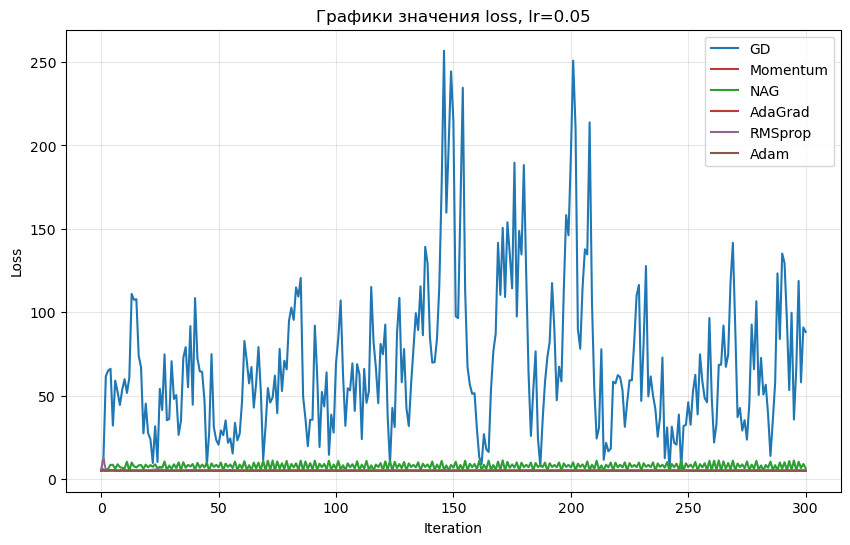

In [4]:
plt.figure(figsize=(10, 6))
for name, info in results.items():
    plt.plot(info["loss"], label=f"{name}")
plt.title(f"Графики значения loss, lr=0.05")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

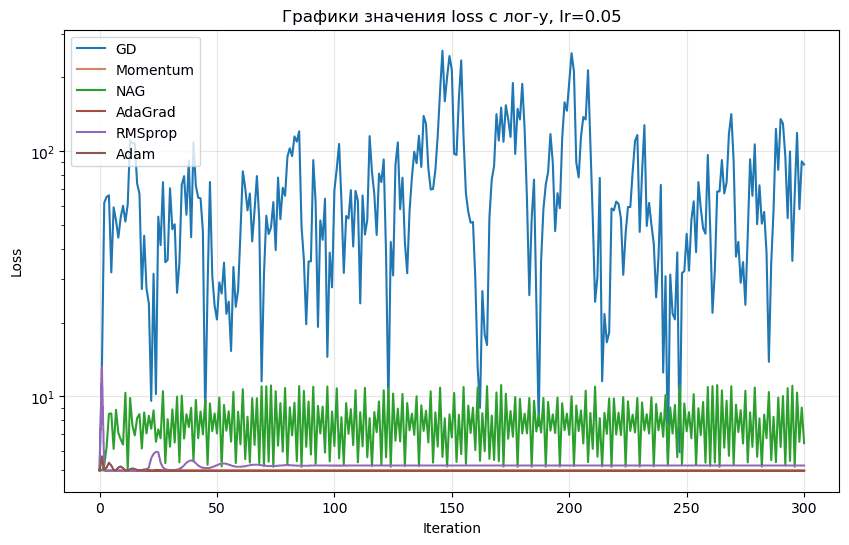

In [5]:
plt.figure(figsize=(10, 6))
for name, info in results.items():
    plt.plot(info["loss"], label=f"{name}")
plt.title(f"Графики значения loss с лог-y, lr=0.05")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

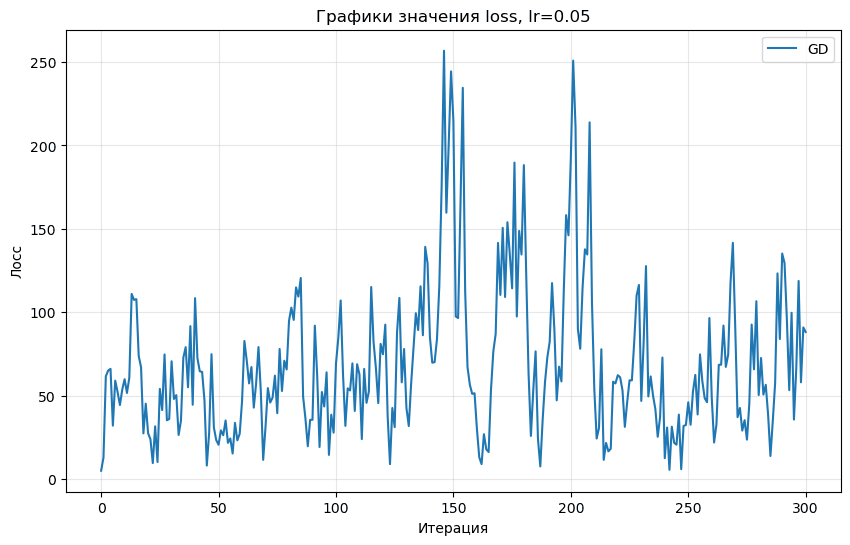

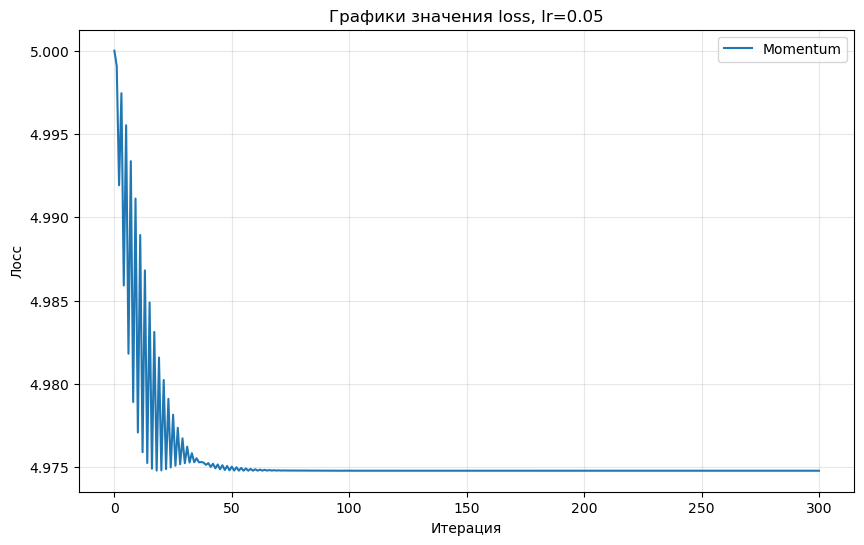

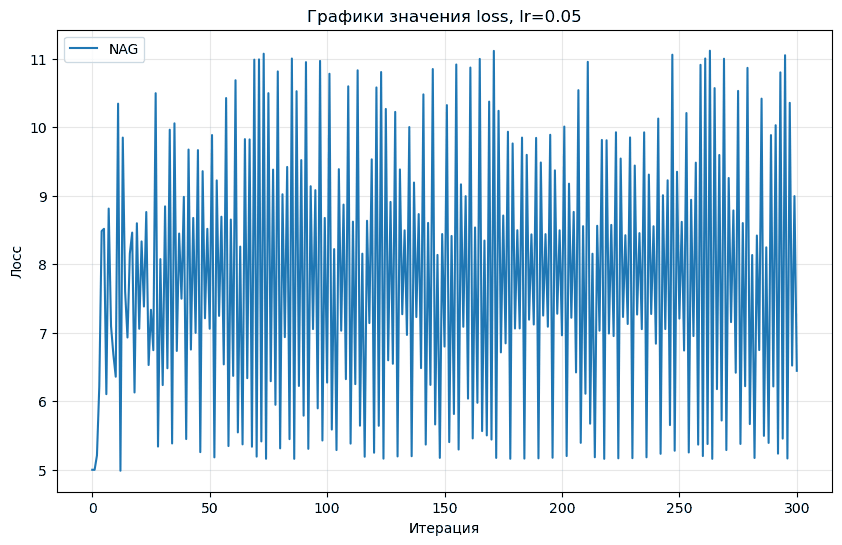

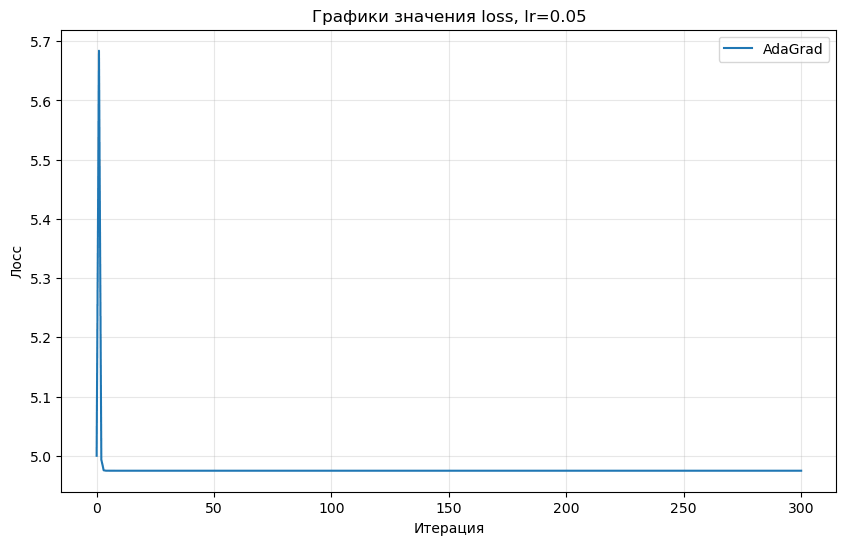

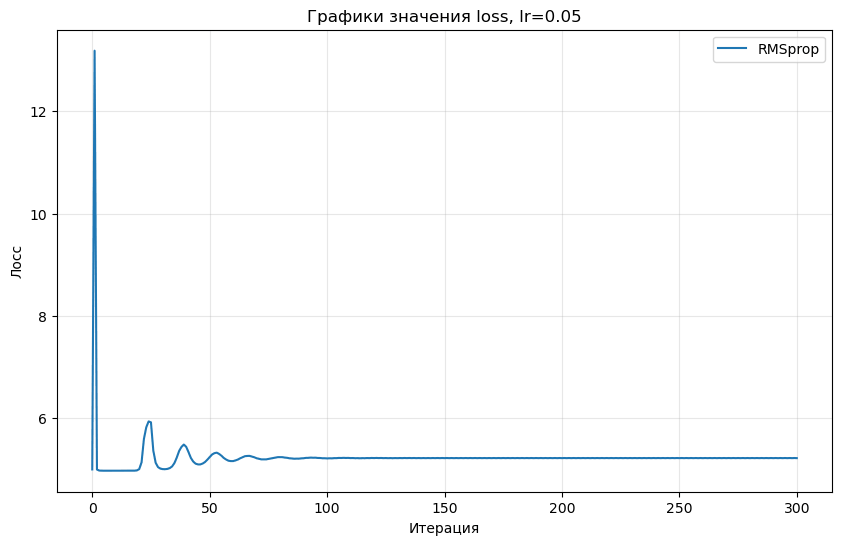

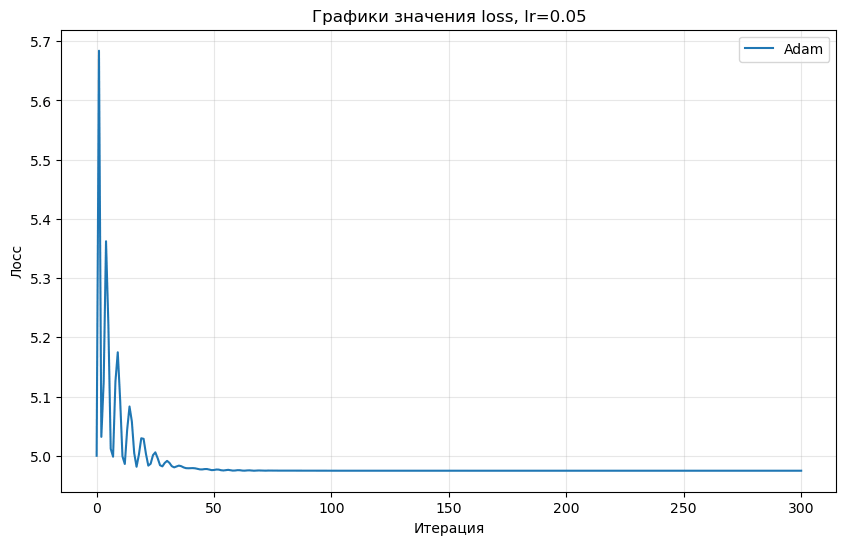

In [6]:
for name, info in results.items():
    plt.figure(figsize=(10, 6))
    plt.plot(info['loss'], label=f'{name}')
    plt.title(f'Графики значения loss, lr=0.05')
    plt.xlabel('Итерация')
    plt.ylabel('Лосс')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

In [7]:
# plt.figure(figsize=(10, 6))
# for name, info in results.items():
#     if name in ['GD', 'NAG', 'RMSprop']: 
#         pass
#     else:
#         plt.plot(info["loss"], label=f"{name}")
# plt.title(f"Графики значения loss, lr=0.05")
# plt.xlabel("Iteration")
# plt.ylabel("Loss")
# plt.grid(True, alpha=0.3)
# plt.legend()
# plt.show()

На основе графиков **не сошлись GD, NAG**, остальные спуски сошлись.

- у GD loss не убывает, сильные скачки на всём протяжении графика
- у NAG амплитуда колебаний не сокращается а держится между 5 и 11, так как вероятно из-за большого шага метод перепрыгивает впадину
- Momentum достиг плато где-то до 50 итерации
- Adam - затухающие колебания и быстрое достижение плато
- RMSprop - если более яркие колебания в начале, до 100 итерации достигается плато
- AdaGrad - метод практически сразу сошелся

In [8]:
def go_optimizers(lr, n_iter=300, initial_point=np.array([-1.0, 2.0], dtype=float)):
    optimizers = {
        'GD':       VanillaGD(learning_rate=lr, n_iterations=n_iter),
        'Momentum': MomentumGD(learning_rate=lr, n_iterations=n_iter, beta=0.9),
        'NAG':      NesterovGD(learning_rate=lr, n_iterations=n_iter, beta=0.9),
        'AdaGrad':  AdaGrad(learning_rate=lr, n_iterations=n_iter),
        'RMSprop':  RMSprop(learning_rate=lr, n_iterations=n_iter, beta=0.9),
        'Adam':     Adam(learning_rate=lr, n_iterations=n_iter),
    }

    results = {}
    for name, optimizer in optimizers.items():
        final_params = optimizer.fit(rastrigin_function, rastrigin_gradient, initial_point)
        results[name] = optimizer.history
        print(f"{name:12s}: Final loss = {rastrigin_function(final_params):.6f}, "
              f"Params = [{final_params[0]:.4f}, {final_params[1]:.4f}]")
    return results, final_params
    
def visual(results, lr):
    for name, info in results.items():
        plt.figure(figsize=(10, 6))
        plt.plot(info['loss'], label=f'{name}')
        plt.title(f'Графики loss {name}, lr={lr}')
        plt.xlabel('Итерация')
        plt.ylabel('Лосс')
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()

Learning rate равен 0.01
GD          : Final loss = 22.872699, Params = [-0.9783, 2.3577]
Momentum    : Final loss = 4.974790, Params = [-0.9950, 1.9899]
NAG         : Final loss = 4.974790, Params = [-0.9950, 1.9899]
AdaGrad     : Final loss = 4.974790, Params = [-0.9950, 1.9899]
RMSprop     : Final loss = 4.984687, Params = [-1.0000, 1.9949]
Adam        : Final loss = 4.974790, Params = [-0.9950, 1.9899]


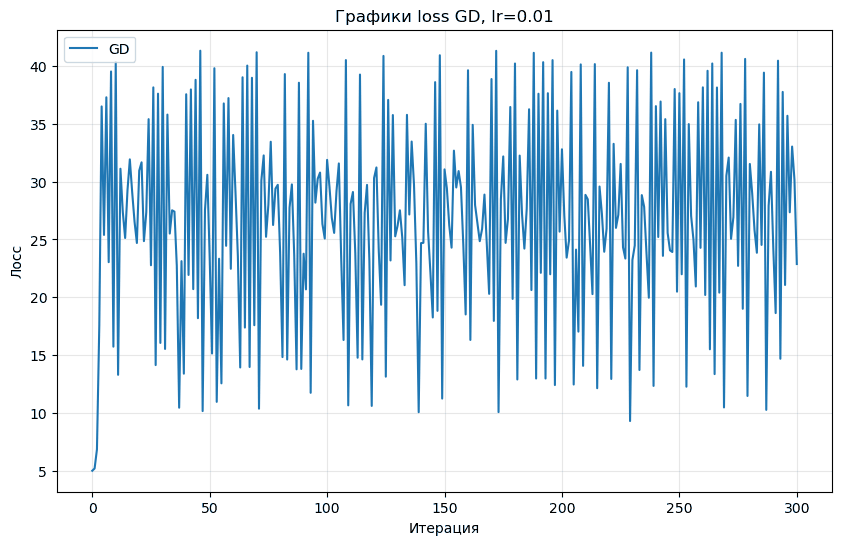

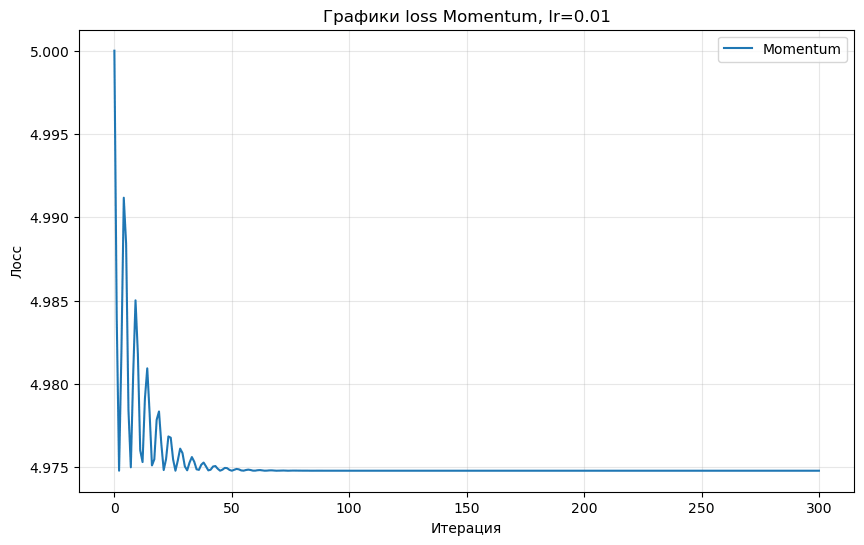

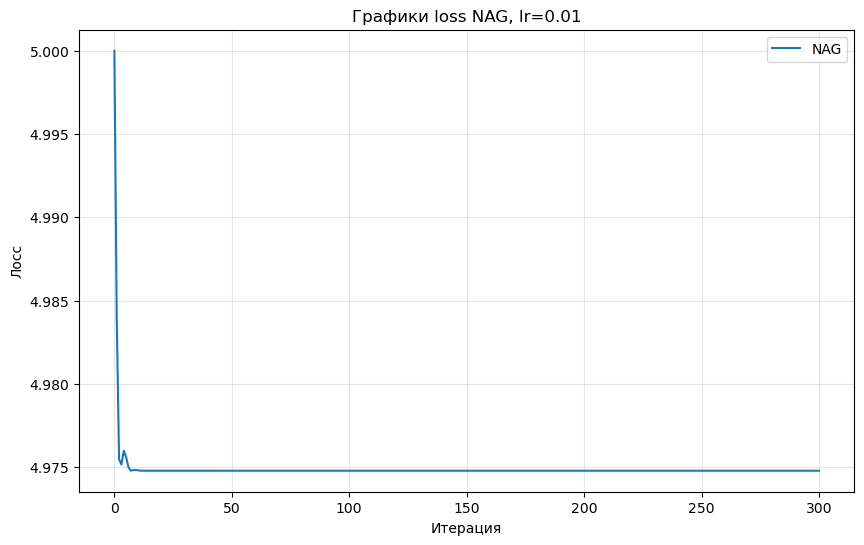

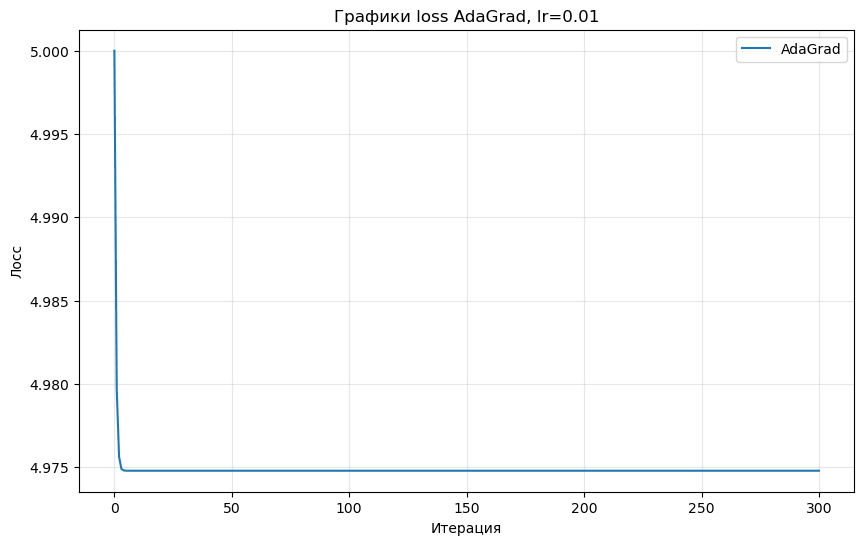

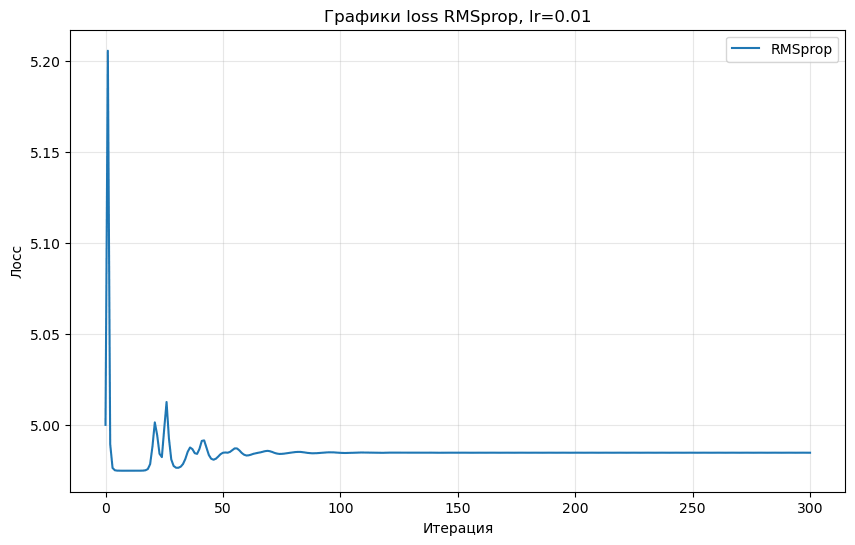

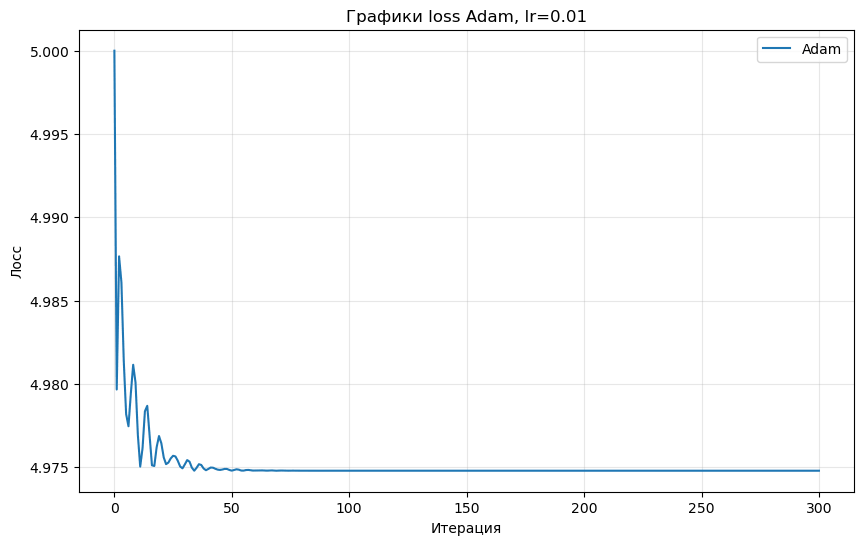

Learning rate равен 0.05
GD          : Final loss = 88.151087, Params = [1.8663, -8.8893]
Momentum    : Final loss = 4.974790, Params = [-0.9950, 1.9899]
NAG         : Final loss = 6.444999, Params = [-1.0255, 2.0709]
AdaGrad     : Final loss = 4.974790, Params = [-0.9950, 1.9899]
RMSprop     : Final loss = 5.220721, Params = [-1.0199, 2.0148]
Adam        : Final loss = 4.974790, Params = [-0.9950, 1.9899]


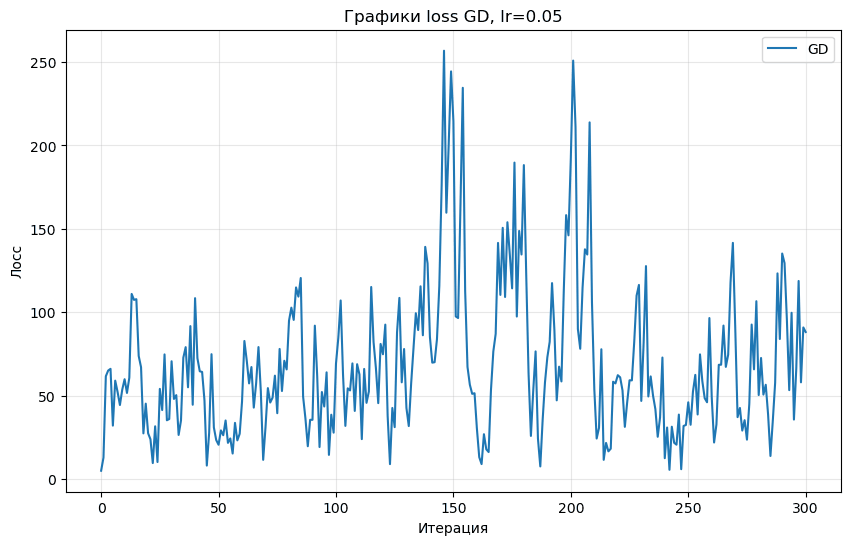

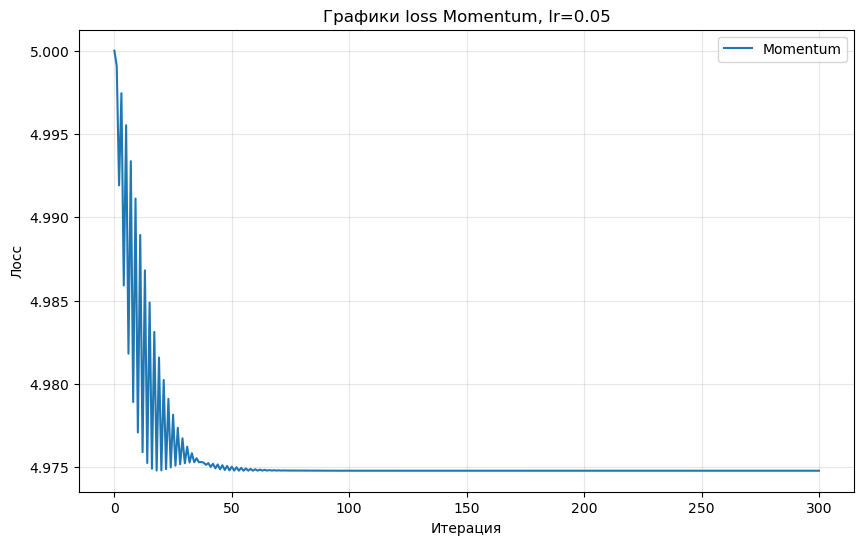

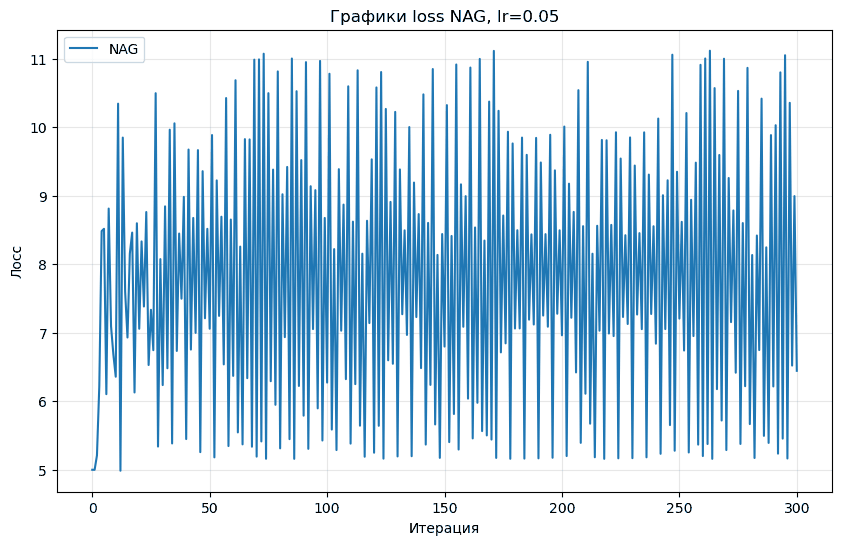

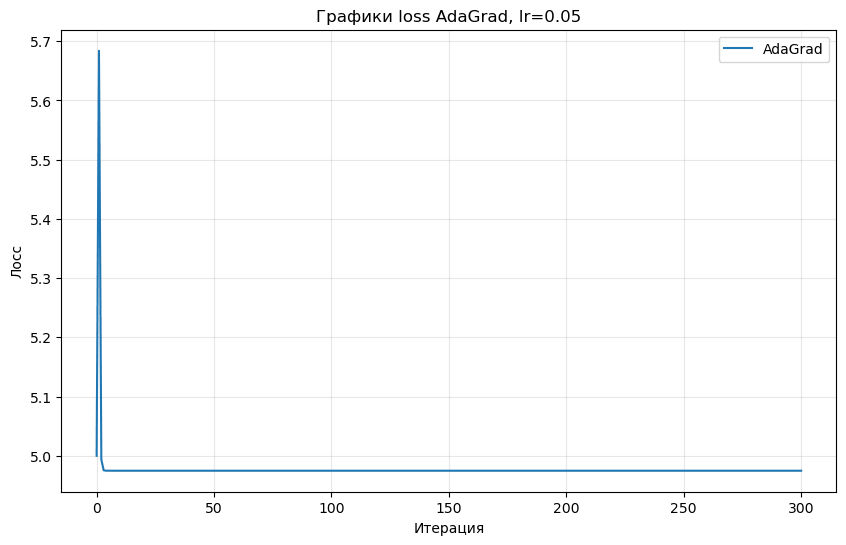

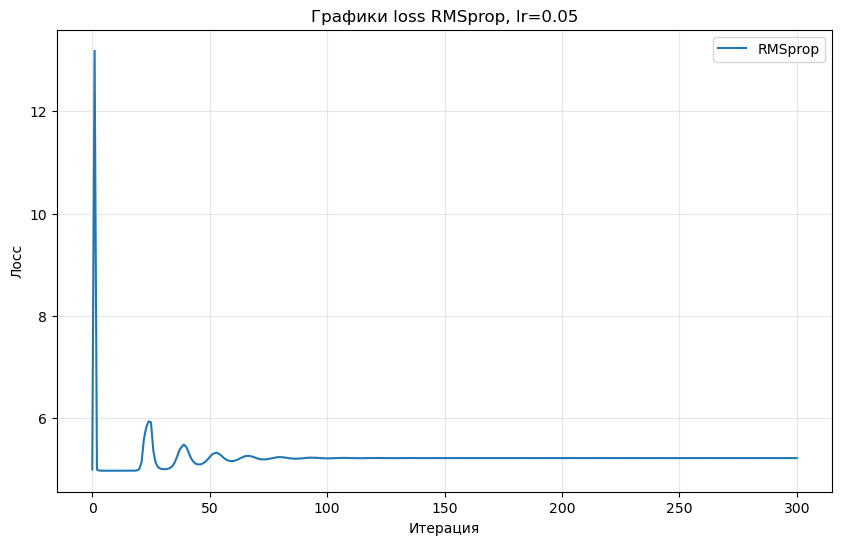

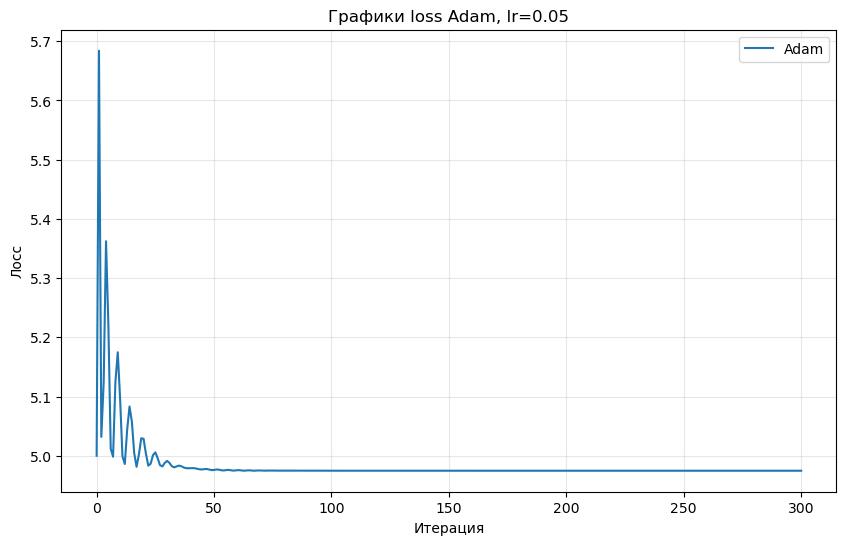

Learning rate равен 0.1
GD          : Final loss = 248.672193, Params = [-13.1330, 8.1834]
Momentum    : Final loss = 7.378101, Params = [-1.0745, 2.0670]
NAG         : Final loss = 43.054585, Params = [-2.1036, 5.9056]
AdaGrad     : Final loss = 4.974790, Params = [-0.9950, 1.9899]
RMSprop     : Final loss = 5.947148, Params = [-1.0447, 2.0394]
Adam        : Final loss = 4.974790, Params = [-0.9950, 1.9899]


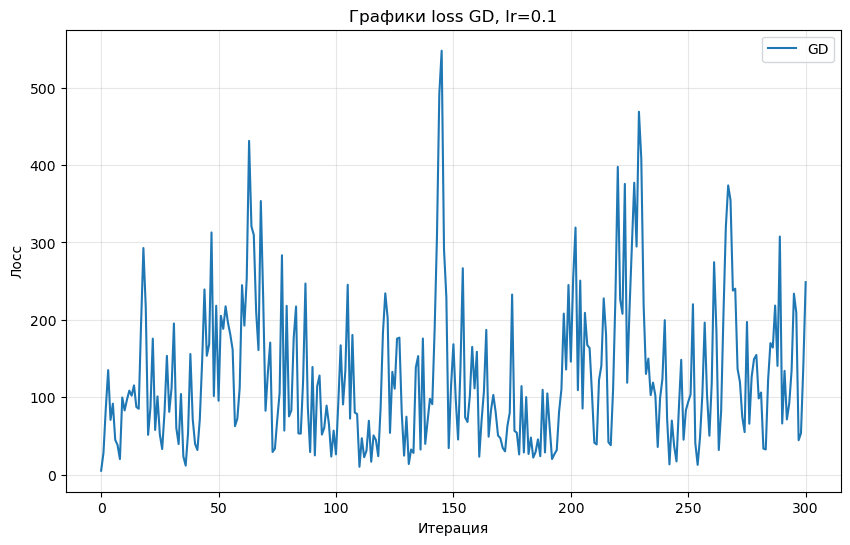

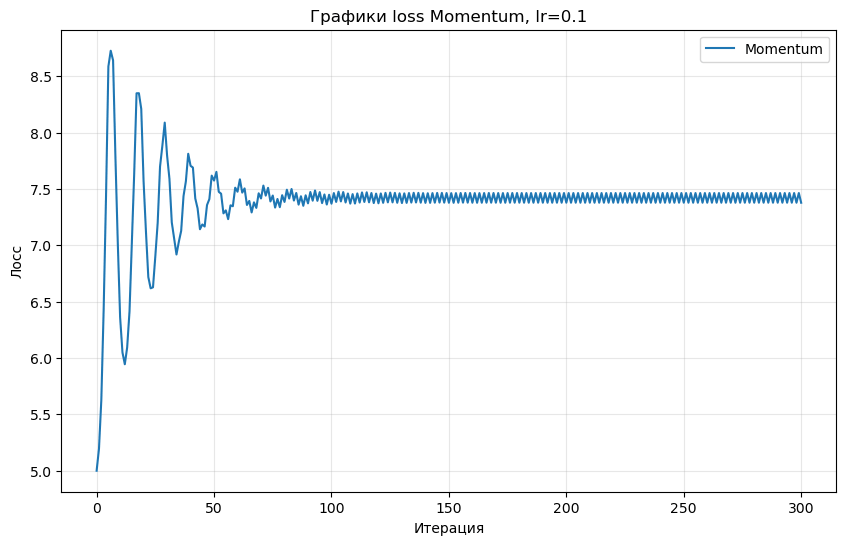

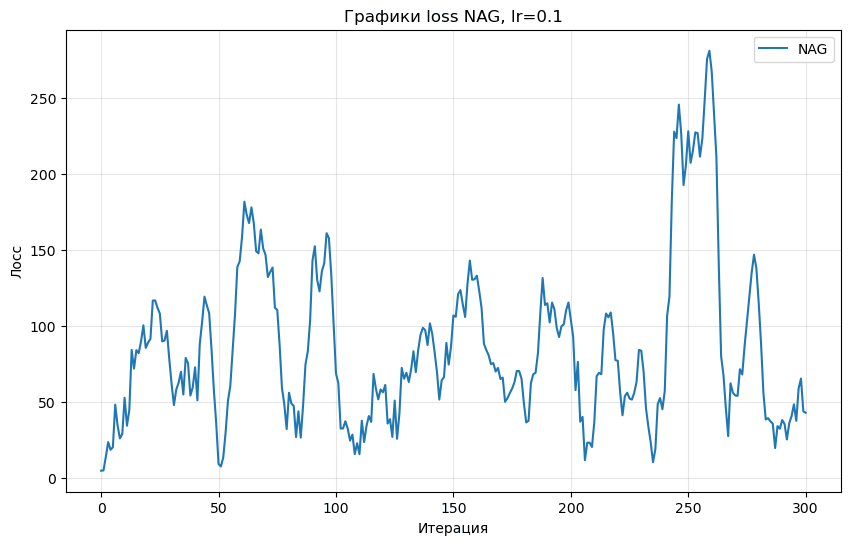

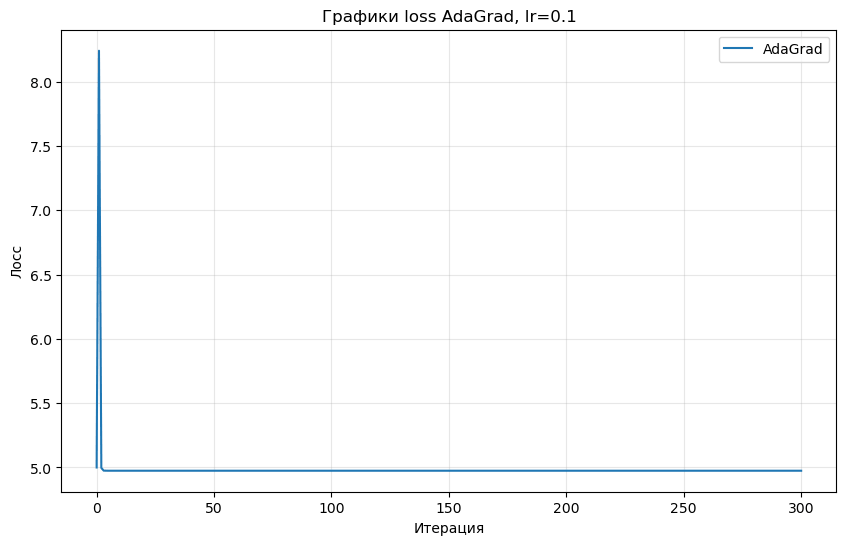

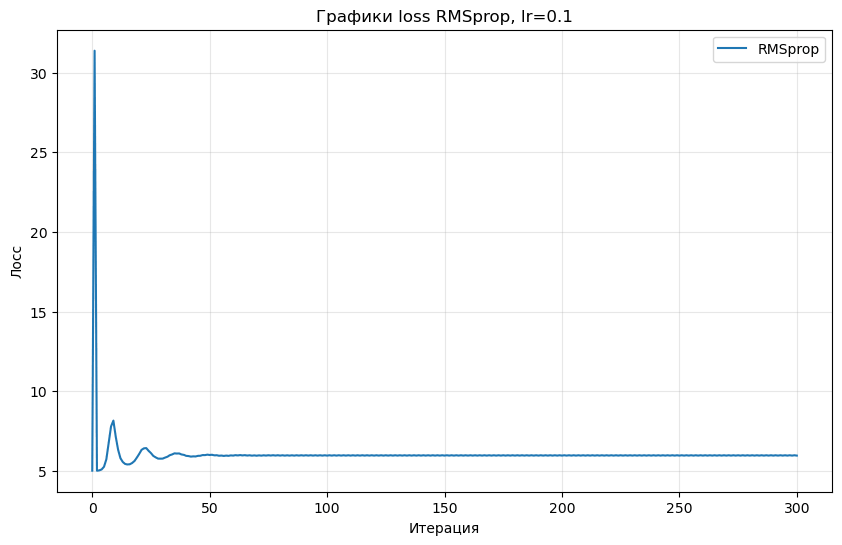

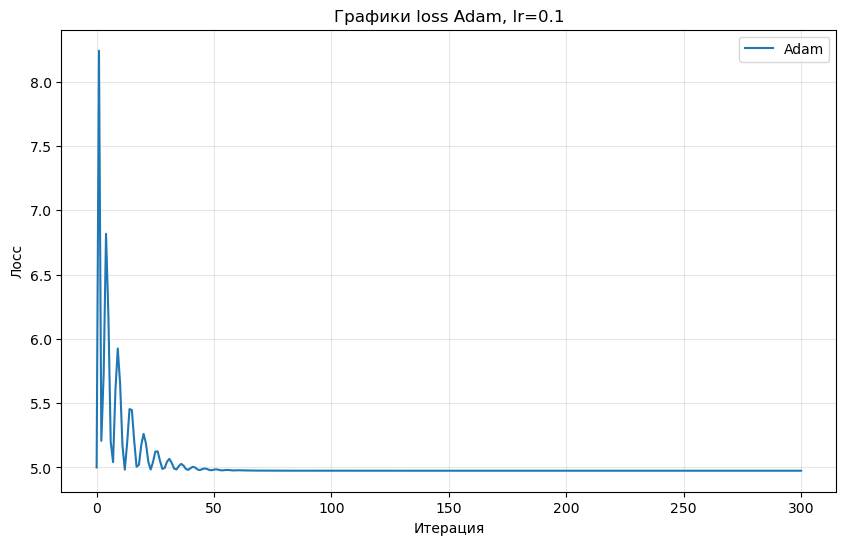

Learning rate равен 0.5
GD          : Final loss = 1667.287210, Params = [-28.4781, 28.7901]
Momentum    : Final loss = 625.134591, Params = [5.5982, 23.9922]
NAG         : Final loss = 1006.876918, Params = [-22.9723, -21.4404]
AdaGrad     : Final loss = 0.994959, Params = [-0.0000, 0.9950]
RMSprop     : Final loss = 38.034295, Params = [1.6544, 0.4469]
Adam        : Final loss = 0.000000, Params = [0.0000, -0.0000]


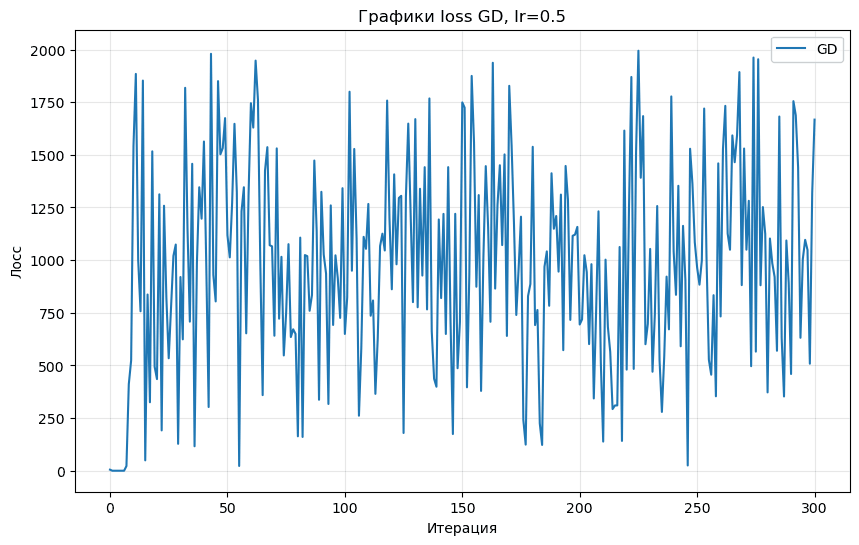

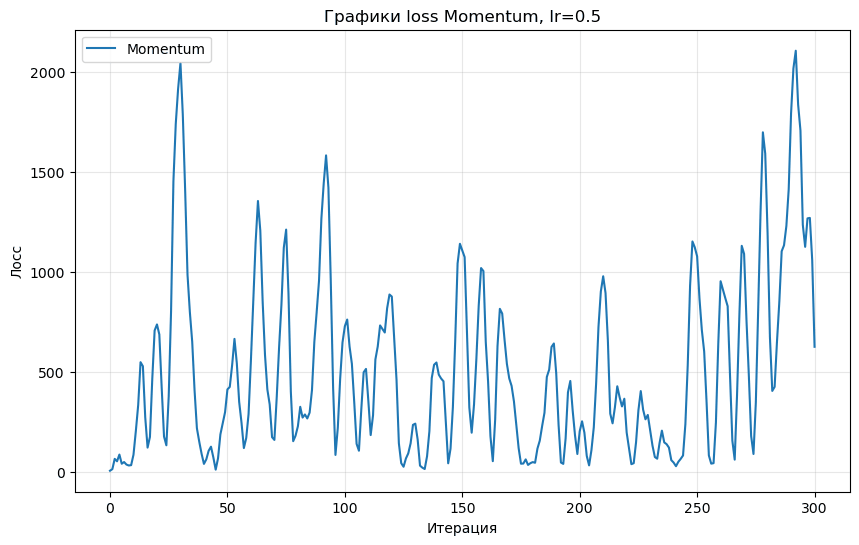

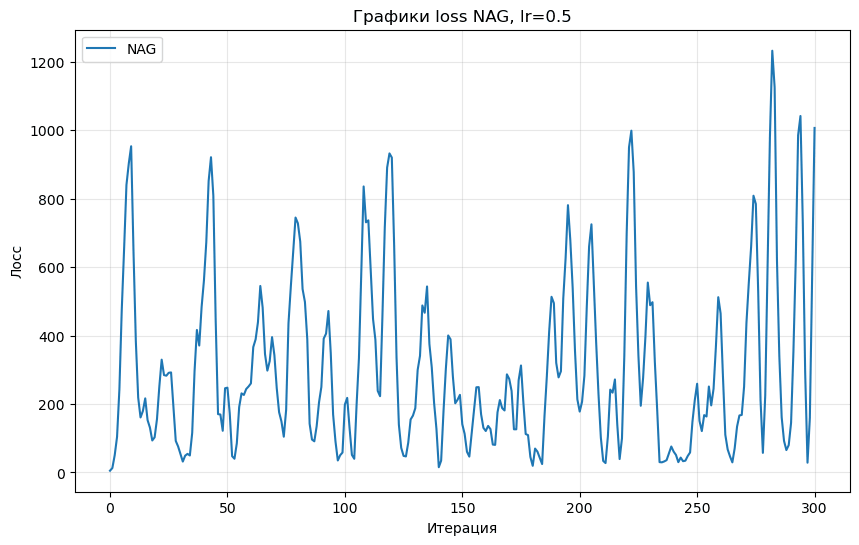

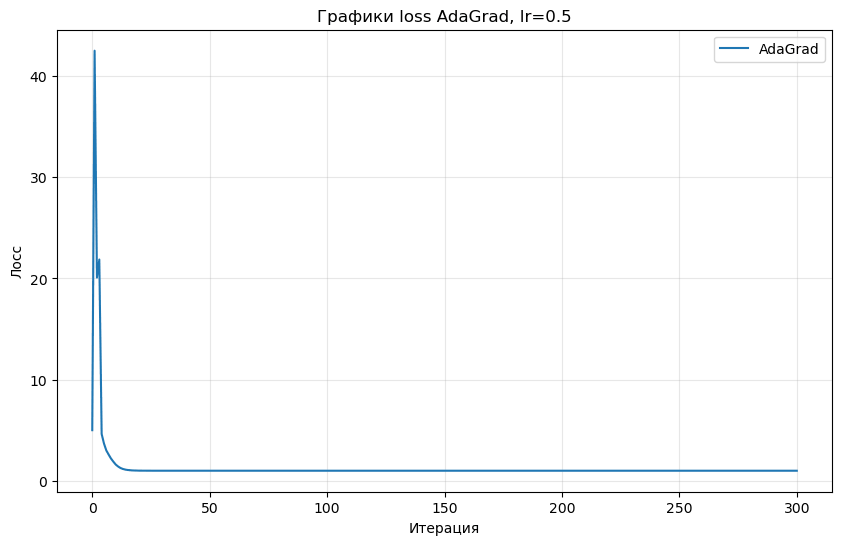

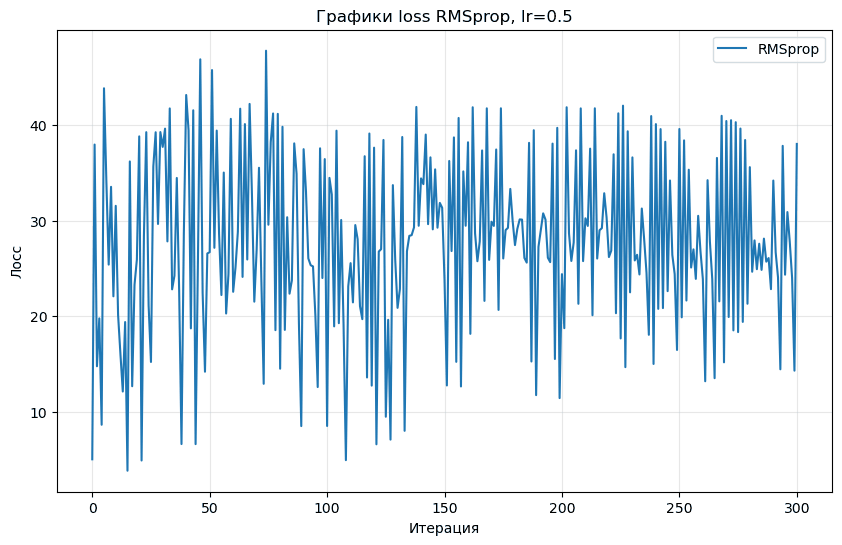

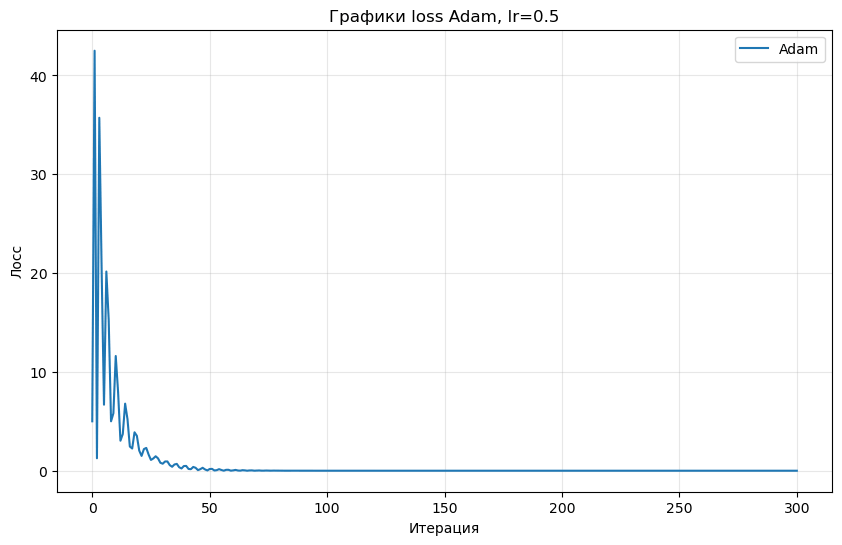

In [9]:
for lr in [0.01, 0.05, 0.1, 0.5]:
    print('Learning rate равен', lr)
    res, final_params = go_optimizers(lr)
    visual(res, lr)

**Вывод по эксперименту**

- При меньшем шаге (0.01) не сошелся только GD, но его итоговый loss стал в 4 раза меньше, а аплитуда колебаний заметно сократилась в сравнении с предыдущим варианте, NAG теперь вышел на плато практически сразу, у Momentum лосс в изначальных итерациях стал более плавно угасать, для остальных методов сильных изменений не было
- При увеличении шага (0.1) сошлись только методы AdaGrad и Adam, они достигли прежний локальный минимум, а также RMSprop, который вышел в плано, но на точке отличной от предыдущих методов, амплитуда колебаний GD стала еще больше, его финальный лосс тоже, Momentum стал колебаться около loss 7.3-7.5, заметно увеличилась амплитуда колебаний NAG
- При шаге 0.5 **Adam достиг глобального минимума**, а метод **AdaGrad оказался близко к нему**, GD, NAG, Momentum и RMSprop не сошлись, у всех за исключением последнего амплитуда многократно увеличилась и лосс достигал 4-значных чисел
- Таким образом, метод Adam благодаря достаточно большим шагам первых итераций смог преодолеть локальный минимум, при этом благодаря нормализации метод не улетел, как его коллеги, шаги быстро уменьшаются и достигают глобального минимума около 50 итерации

### **Задание 3. Будь выпуклым (3 балла)**



На протяжении курса вы могли заметить, что мы всегда предпочитаем выпуклые функции потерь. Но насколько это требование жесткое? Давайте рассмотрим простейшую логистическую регрессию.

Модель:

$$p(x; w) = \sigma(z) = \sigma(w^\top x), \quad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Стандартный log-loss для одного объекта:

$$L_{\log}(p, y) = -\big( y \log p + (1-y)\log(1-p)\big), \quad y \in {0, 1}.$$

Рассмотрим для неё модифицированный loss — без логарифма. Просто опустим его, оставив линейную комбинацию вероятностей.

$$L_{\text{no-log}}(p, y) = -\big( y p + (1-y)(1-p)\big)$$


#### **3. 1. Логарифм? (2 балла)**

Попробуем понять, зачем вообще нам нужен логарифм.

1. Выведите производную logloss'a  без логарифма по $p$ **(только по $p$, по $w$ не надо!)**. Что получилось? Подумайте (погуглите), почему на практике используют логарифм.

2. Сравните качество:

   * обучите логистическую регрессию с обычным log-loss,
   * обучите с модифицированным loss без log,
   * сравните качество моделей. Поясните результаты.

  **В функциях градиенты должны быть уже по W**


**ответ**
Производная по p не зависит от p:

$$L_{\text{no-log}}(p, y) = −1+y+p−2yp$$
$$∂L/∂p = 0+0+1−2y$$
$$∂L/∂p = 1−2y$$

Если y=1, то производная будет -1, если y=0, то производная +1

- На практике используют log loss, так как он гарантирует, что в рамках модели максимального правдоподобия мы получаем корректные, интерпретируемые вероятности, его оптимизация хорошо обусловлена, тогда как используя no-log loss мы получаем не вероятности, у no-log loss мы  минимизируем сумму эмпирических потерь.
- Log loss сильно штрафует модель за уверенность в неверном ответе. Если y=1, а предсказание модели около 0, лосс стремится к бесконечности. Тогда как в случае no-log loss штрафует сильнее за неполную уверенность в правильном ответе, чем за полную уверенность в неправильном ответе.
-  Градиент Log loss пропорционален ошибке (p−y) и входному признаку x, тогда как в no-log loss градиент затухает пропорционально p(1−p), то есть когда модель практически уверена в правильном ответе градиент становится маленьким, и обучение практически прекращается, что может быть проблемой на ранних этапах обучения
-  Log loss является выпуклой функцией по w, а значит gd с наибольшей вероятностью найдет глобальный минимум,  no-log loss не является выпуклой по w при композиции с сигмоидой, значит может быть множество локальных минимумов

Теперь сравним качество на практике:

In [10]:
# Генерация данных
X_class, y_class = make_classification(
    n_samples=1000,
    n_features=30,
    n_informative=20,
    random_state=42
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_class)
X_with_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])  # добавляем bias-столбец


# Функции для лосса
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


# Стандартный логистический log-loss
def logistic_loss(weights, X, y):
    """
    L_log(w) = - mean( y log p + (1-y) log(1-p) ),  p = sigmoid(X w)
    """
    z = X @ weights
    p = sigmoid(z)
    return - np.mean(y*np.log(p) + (1-y) * np.log(1-p))


def logistic_gradient(weights, X, y):
    """
    grad_w L_log(w) = X^T (p - y) / N,  где p = sigmoid(X w)
    """
    z = X @ weights
    p = sigmoid(z)
    n = X.shape[0]
    return X.T @ (p - y) / n

def without_log_loss(weights, X, y):
    """
    Log-loss без логарифма"
        L_no_log(w) = - mean( y p + (1 - y)(1 - p) ), p = sigmoid(X w)
    """
    z = X @ weights
    p = sigmoid(z)
    return - np.mean(y * p + (1-y)*(1-p))


def without_log_loss_grad(weights, X, y):
    """
    Градиент L_no_log по w:
        dL/dp = 1 - 2y
        dp/dz = p (1-p)
        z = X w

    grad_w L_no_log = X^T * [ (1 - 2y) * p (1-p) ] / N
    """
    z = X @ weights
    p = sigmoid(z)
    n = X.shape[0]
    c = (1 - 2*y) * p * (1-p)
    return (X.T @ c) / n
    

Проверим результаты.

* далее везде используйте класс оптимизатора (`VanillaGD`) и одинаковую инициализацию весов;
* для каждой модели реализуйте свои `loss_fn` и `grad_fn` и передайте их в `fit` через `lambda`:

  ```python
  gd_log = VanillaGD(...)
  w_log = gd_log.fit(
      loss_fn=lambda w: logistic_loss(w, X_with_bias, y),
      grad_fn=lambda w: logistic_gradient(w, X_with_bias, y),
      initial_params=initial_weights
  )
  ```

  и аналогично для `no_log_loss` / `no_log_loss_grad`. Так всё заработает.

In [11]:
initial_weights = np.ones(X_with_bias.shape[1])

# Логистическая регрессия с log-loss
gd_log = VanillaGD(learning_rate=0.5, n_iterations=200)
w_log = gd_log.fit(
      loss_fn=lambda w: logistic_loss(w, X_with_bias,  y_class),
      grad_fn=lambda w: logistic_gradient(w, X_with_bias,  y_class),
      initial_params=initial_weights
  )

# Логистическая регрессия с no-log loss
gd_no = VanillaGD(learning_rate=0.5, n_iterations=200)
w_no = gd_no.fit(
      loss_fn=lambda w: without_log_loss(w, X_with_bias, y_class),
      grad_fn=lambda w: without_log_loss_grad(w, X_with_bias, y_class),
      initial_params=initial_weights
)

def accuracy(weights):
    p = sigmoid(X_with_bias @ weights)
    y_pred = (p >= 0.5).astype(int)
    return (y_pred == y_class).mean()

print("\n=== Итоговые результаты (VanillaGD) ===")
print(f"log-loss:    final_loss = {logistic_loss(w_log, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_log):.4f}")
print(f"no-log loss: final_loss = {without_log_loss(w_no, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_no):.4f}")


=== Итоговые результаты (VanillaGD) ===
log-loss:    final_loss = 0.3976, accuracy = 0.8110
no-log loss: final_loss = -0.7195, accuracy = 0.7330


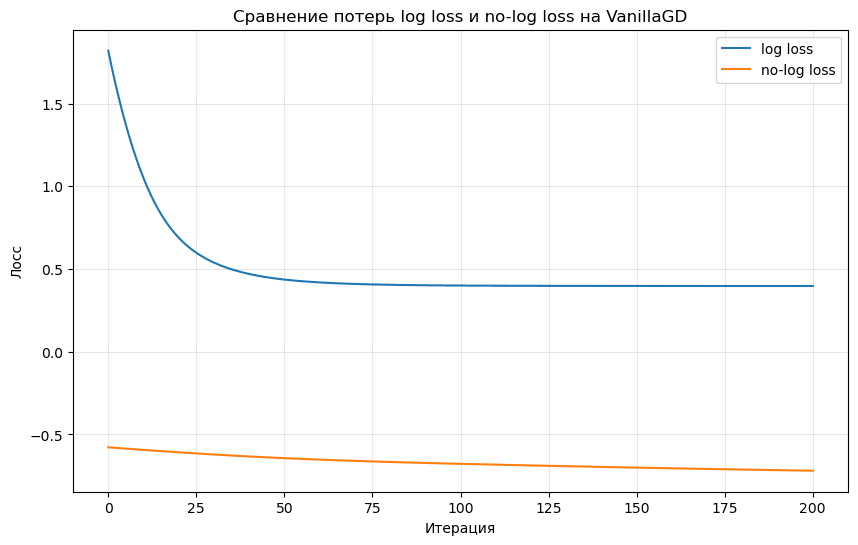

In [12]:
# ваш код здесь — постройте график лосса
plt.figure(figsize=(10, 6))
plt.plot(gd_log.history['loss'], label='log loss')
plt.plot(gd_no.history['loss'], label='no-log loss')
plt.title('Сравнение потерь log loss и no-log loss на VanillaGD')
plt.xlabel('Итерация')
plt.ylabel('Лосс')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Сравнение резульатов**
- log loss показывает лучшее качество модели по метрике accuracy, то есть он более эффективный классификатор
- у no-log loss лосс всегда находится в диапазоне от 0 до -1 (-1, если идеально), лосс у log loss находится в диапазоне от 0 до +бесконечности (0 - если идеально) - то есть у обеих моделей лосс уменьшался с итерациями в сторону идеального значения, при этом изменения в log loss были более значительными и стабилизировались где-то на 50 итерации, у no-loss постепенно лосс постепенно сокращался
- принципиальная разница между методами - учет уверенности ошибки при штрафе, в модели log loss градиент становится очень большим из-за того, что чем меньше p, тем больше становится лосс, большой градиент повлечет за собой сильное обновление весов, что приведет к исправлению существующей ошибки, у no-log loss градиент меньше на серьезных ошибках, то есть модель не учится на значительных ошибках, что отражается на обучаемости и качестве модели

#### **3. 2. И снова анализ (1 балл)**

Подумайте над результатами задания.
- Почему no-log выдал меньший loss? Значит ли это, что мы можем его использовать?
- Что будет, если подобрать гиперпараметр скорости спуска и попробовать другие оптимизаторы?

Реализуйте ваши эксперименты. За каждый — 0.5 балла (суммарно максимум 1 балл).

- no-log выдал меньший loss (отрицательный) из-за диапазона, в котором всегда находится лосс данной модели, численное значение всегда будет меньше, чем для log loss, при этом качество log loss вероятнеее всего будет всегда лучше благодаря лучшей адаптивности при штрафах и более точной обучаемсти модели
- попробуем подобрать другой оптимизатор и другой шаг


=== Итоговые результаты для шага 0.01===
log-loss:    final_loss = 1.4552, accuracy = 0.6110
no-log loss: final_loss = -0.5844, accuracy = 0.5790


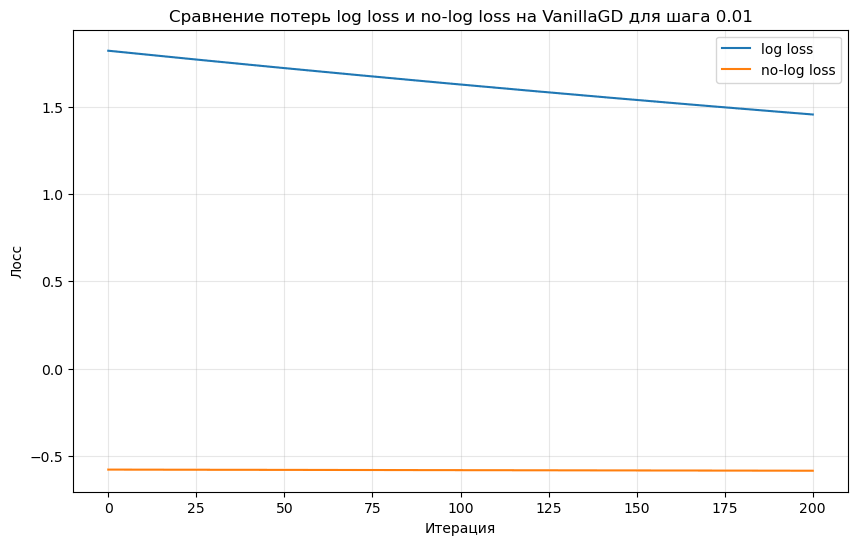


=== Итоговые результаты для шага 0.05===
log-loss:    final_loss = 0.6941, accuracy = 0.7150
no-log loss: final_loss = -0.6082, accuracy = 0.6050


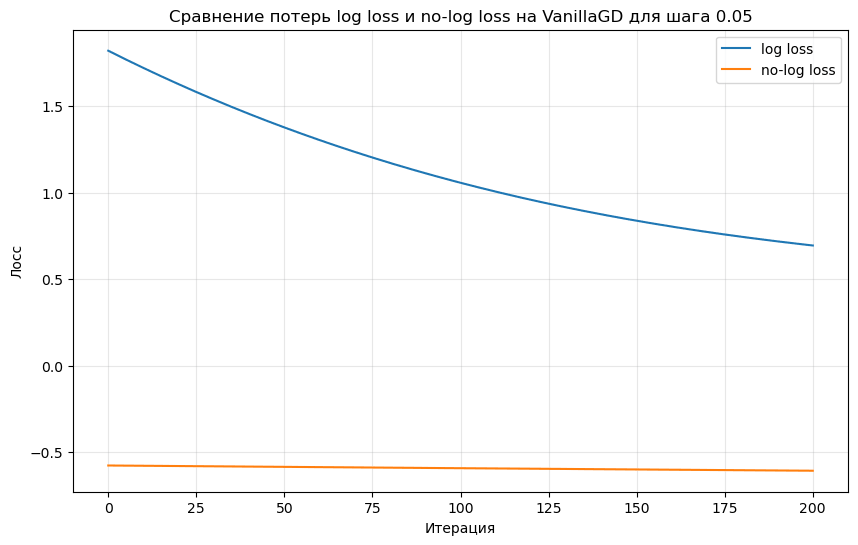


=== Итоговые результаты для шага 0.1===
log-loss:    final_loss = 0.4714, accuracy = 0.7890
no-log loss: final_loss = -0.6333, accuracy = 0.6390


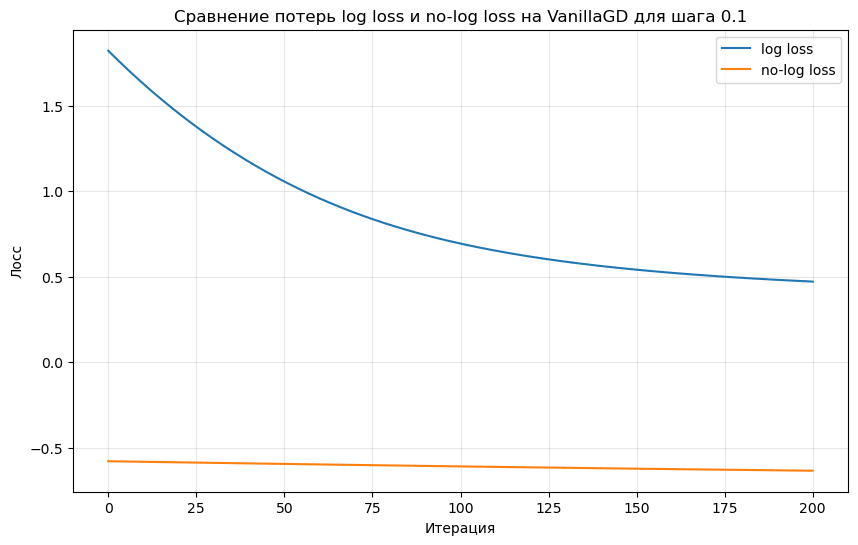


=== Итоговые результаты для шага 0.7===
log-loss:    final_loss = 0.3975, accuracy = 0.8110
no-log loss: final_loss = -0.7424, accuracy = 0.7560


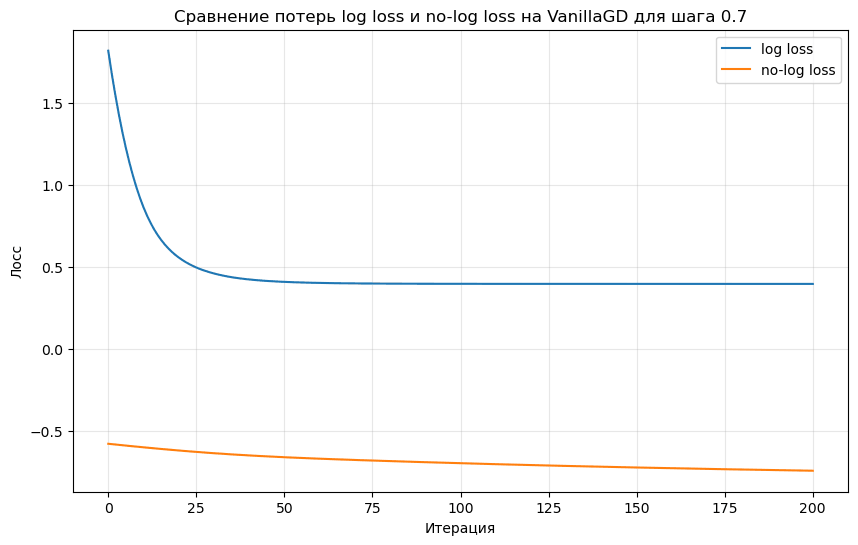


=== Итоговые результаты для шага 1===
log-loss:    final_loss = 0.3975, accuracy = 0.8110
no-log loss: final_loss = -0.7692, accuracy = 0.7870


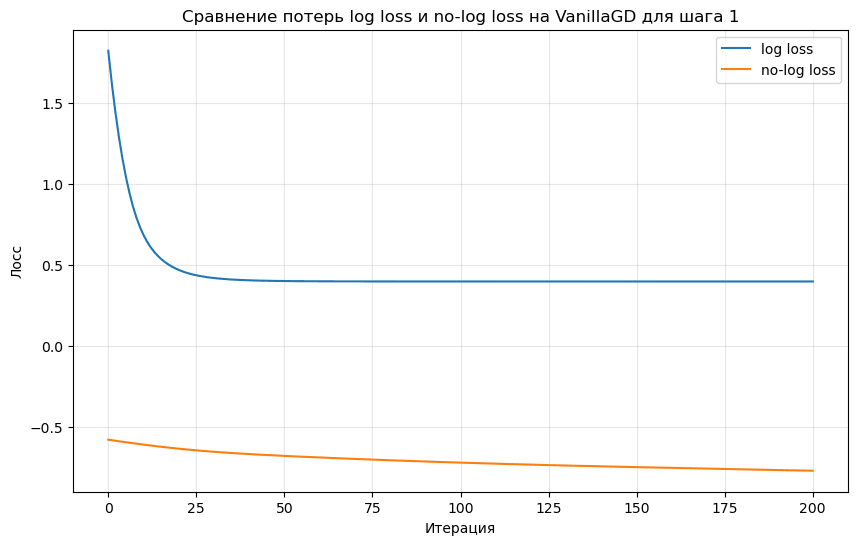


=== Итоговые результаты для шага 5===
log-loss:    final_loss = 0.3975, accuracy = 0.8110
no-log loss: final_loss = -0.8166, accuracy = 0.8290


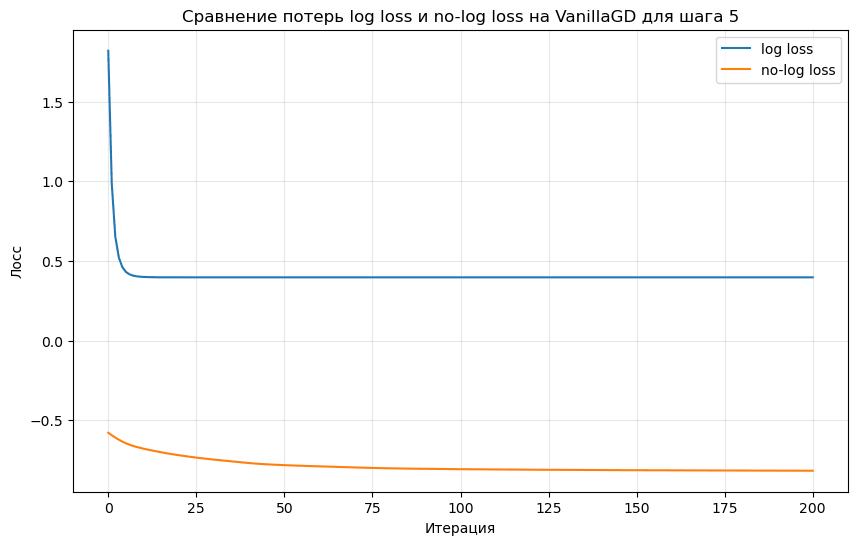


=== Итоговые результаты для шага 10===
log-loss:    final_loss = 0.7672, accuracy = 0.7690
no-log loss: final_loss = -0.8260, accuracy = 0.8440


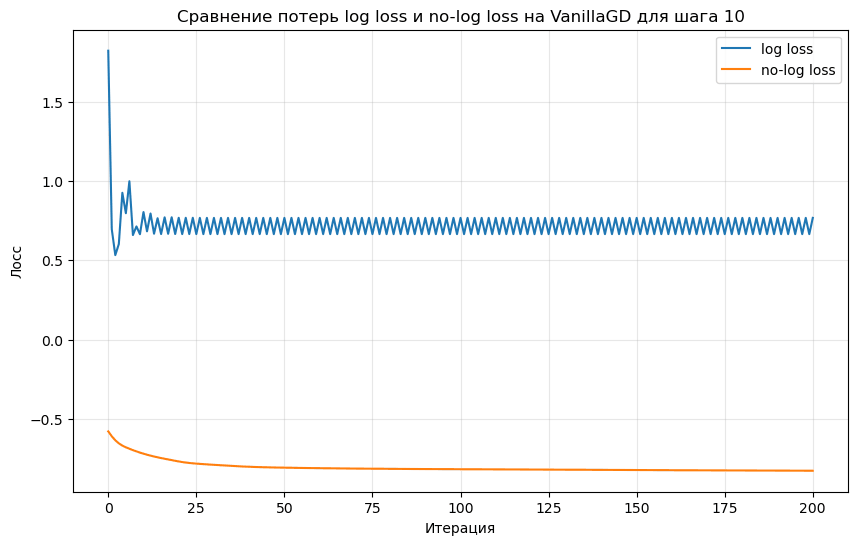

In [13]:
for i in [0.01, 0.05, 0.1, 0.7, 1, 5, 10]:
    gd_log = VanillaGD(learning_rate=i, n_iterations=200)
    w_log = gd_log.fit(
      loss_fn=lambda w: logistic_loss(w, X_with_bias,  y_class),
      grad_fn=lambda w: logistic_gradient(w, X_with_bias,  y_class),
      initial_params=initial_weights
    )
    gd_no = VanillaGD(learning_rate=i, n_iterations=200)
    w_no = gd_no.fit(
      loss_fn=lambda w: without_log_loss(w, X_with_bias, y_class),
      grad_fn=lambda w: without_log_loss_grad(w, X_with_bias, y_class),
      initial_params=initial_weights
    )
    print(f"\n=== Итоговые результаты для шага {i}===")
    print(f"log-loss:    final_loss = {logistic_loss(w_log, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_log):.4f}")
    print(f"no-log loss: final_loss = {without_log_loss(w_no, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_no):.4f}")

    
    plt.figure(figsize=(10, 6))
    plt.plot(gd_log.history['loss'], label='log loss')
    plt.plot(gd_no.history['loss'], label='no-log loss')
    plt.title(f'Сравнение потерь log loss и no-log loss на VanillaGD для шага {i}')
    plt.xlabel('Итерация')
    plt.ylabel('Лосс')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

**Результаты**

- обе модели показали себя по-разному с различными шагами: для каждой нужен свой шаг, чтобы модель получилась эффективной из-за разного влияния градиента
- при маленьком шаге (0.01, 0.05) веса обновляются очень медленно и за 200 итераций модели не успевают обучиться
- при lr=0.1: log acc≈0.789, no-log acc≈0.639, то есть log loss уже близок к хорошему результату, тогда как для no-log шаг недостаточно эффективный
- при большом шаге (0.5-1) log loss выходит на плато, no-log начинает улучшать качество, так как диапазон шага становится достаточно большим, чтобы компенсировать слабый градиент при больших ошибках
- при еще большем шаге (5, 10) log loss ухудшается, так как gd перепрыгивает оптимум и возникают колебания, метрика качества падает, тогда как no-log улучшается, так как в первые итерации градиент не маленький и модель успевает обучиться лучше до того как ответы станут уверенными и сократят градиент, что стабилизирует обучение


=== Итоговые результаты для VanillaGD===
log-loss:    final_loss = 0.3976, accuracy = 0.8110
no-log loss: final_loss = -0.7195, accuracy = 0.7330


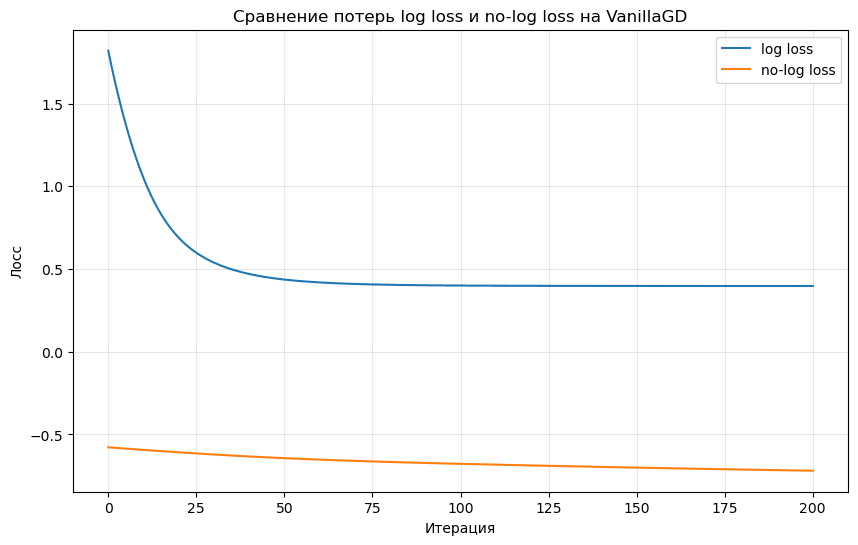


=== Итоговые результаты для MomentumGD===
log-loss:    final_loss = 0.3976, accuracy = 0.8120
no-log loss: final_loss = -0.7160, accuracy = 0.7270


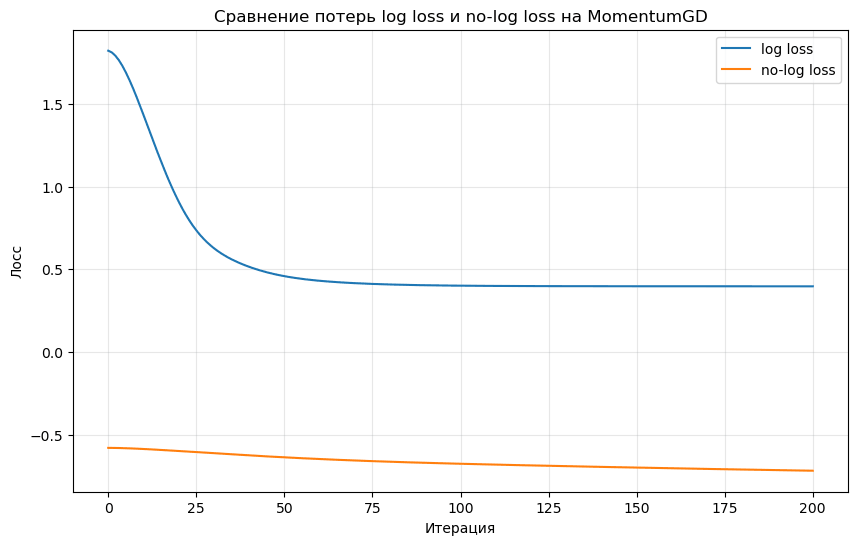


=== Итоговые результаты для NesterovGD===
log-loss:    final_loss = 0.3976, accuracy = 0.8120
no-log loss: final_loss = -0.7161, accuracy = 0.7270


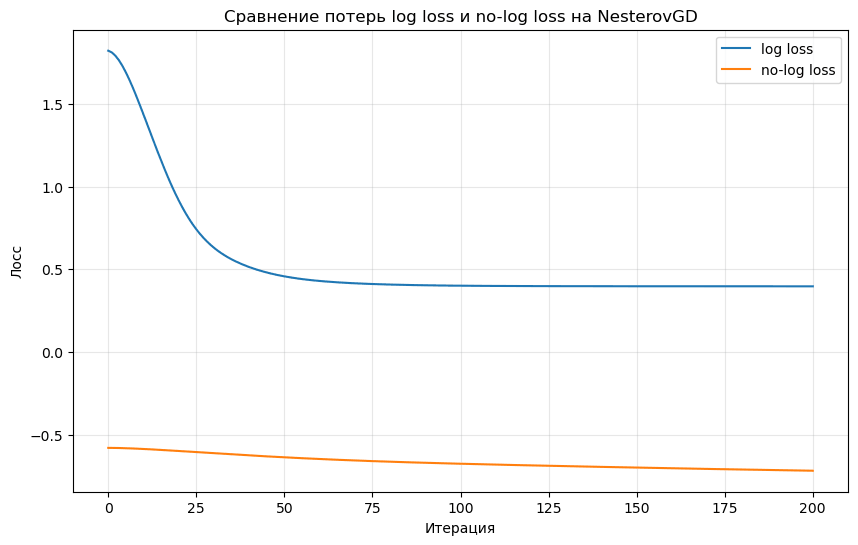


=== Итоговые результаты для AdaGrad===
log-loss:    final_loss = 0.3975, accuracy = 0.8110
no-log loss: final_loss = -0.8274, accuracy = 0.8410


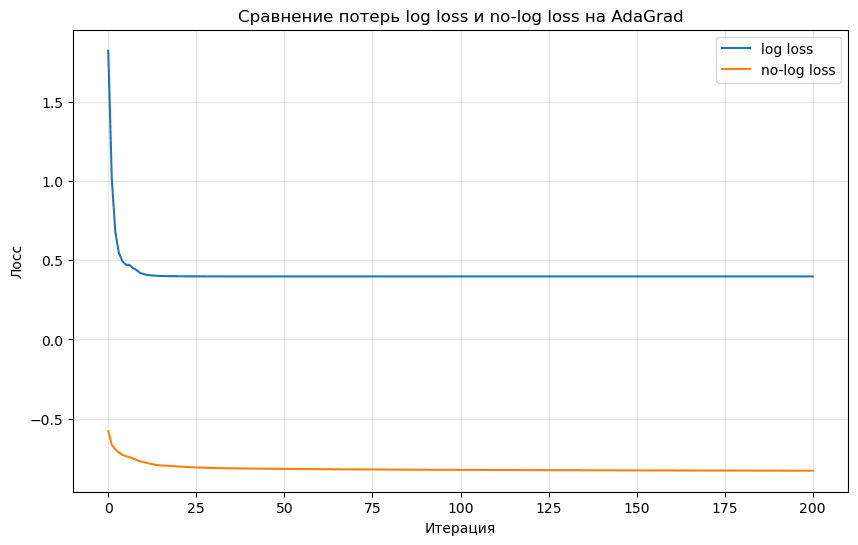


=== Итоговые результаты для RMSprop===
log-loss:    final_loss = 0.6158, accuracy = 0.7810
no-log loss: final_loss = -0.8459, accuracy = 0.8500


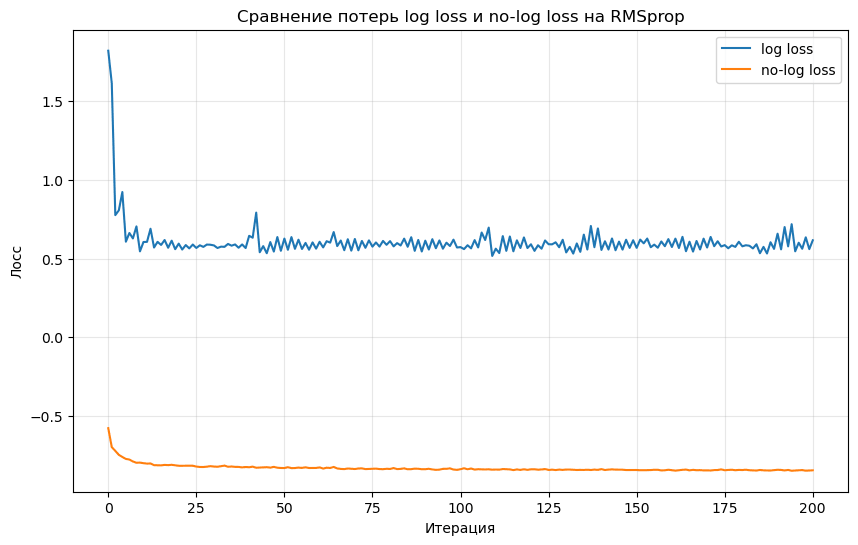


=== Итоговые результаты для Adam===
log-loss:    final_loss = 0.3975, accuracy = 0.8110
no-log loss: final_loss = -0.8430, accuracy = 0.8490


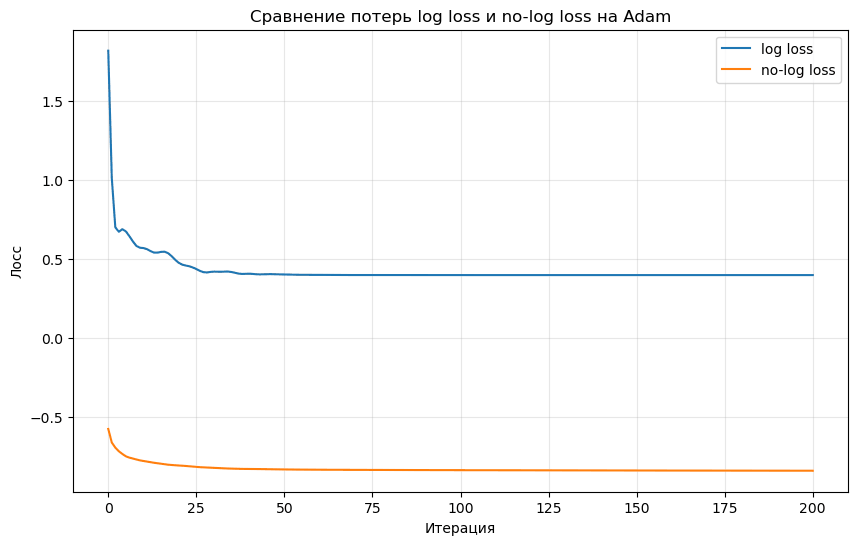

In [14]:
for opt in [VanillaGD, MomentumGD, NesterovGD, AdaGrad, RMSprop, Adam]:
    gd_log = opt(learning_rate=0.5, n_iterations=200)
    w_log = gd_log.fit(
      loss_fn=lambda w: logistic_loss(w, X_with_bias,  y_class),
      grad_fn=lambda w: logistic_gradient(w, X_with_bias,  y_class),
      initial_params=initial_weights
    )
    gd_no = opt(learning_rate=0.5, n_iterations=200)
    w_no = gd_no.fit(
      loss_fn=lambda w: without_log_loss(w, X_with_bias, y_class),
      grad_fn=lambda w: without_log_loss_grad(w, X_with_bias, y_class),
      initial_params=initial_weights
    )
    print(f"\n=== Итоговые результаты для {opt.__name__}===")
    print(f"log-loss:    final_loss = {logistic_loss(w_log, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_log):.4f}")
    print(f"no-log loss: final_loss = {without_log_loss(w_no, X_with_bias, y_class):.4f}, "
      f"accuracy = {accuracy(w_no):.4f}")

    
    plt.figure(figsize=(10, 6))
    plt.plot(gd_log.history['loss'], label='log loss')
    plt.plot(gd_no.history['loss'], label='no-log loss')
    plt.title(f'Сравнение потерь log loss и no-log loss на {opt.__name__}')
    plt.xlabel('Итерация')
    plt.ylabel('Лосс')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

**Результаты**
- практически везде одинаковый результат для log loss: final_loss ≈ 0.398, accuracy ≈ 0.811, получается, что у всех методов, которые сошлись один и тот же минимум, а модель влияет в основном на скорость/траекторию, а не на итоговый результат, исключение - RMSprop, где было больше колебаний и который не достиг минимума за данное число итераций
- no-log loss - адаптивные методы (AdaGrad, RMSprop, Adam) дают accuracy около 0.84, GD, Momentum, NAG показывают результат хуже, около 0.73, что происходит так как адптивные методы увеличивают или стабилизируют шаг, что компенсирует слабый градиент